
# Alteration Analysis for AP1

- **Params:** `eps_steps=4.0`, `DBSCAN_min_samples=4`, `olivine_thresh=65`, `binw_steps=1.0`.


## 1) Configuration — file paths, columns, and parameters

In [1]:

# === File inputs ===
mineral_path = "/Users/a19167/Desktop/PIXL/Carbonate_Research/920/Mike Mineral Phases.csv"
loc_path     = "/Users/a19167/Desktop/PIXL/Carbonate_Research/920/322634245-SIF_0915_0748197693_699FDR_N0450000SRLC08029_0000LMJ02_EXPORT_warp_color2.png-beam-locations.csv"
image_path   = "/Users/a19167/Desktop/PIXL/Carbonate_Research/920/SIF_0915_0748197693_699FDR_N0450000SRLC08029_0000LMJ02_EXPORT_warp_color2.png"
outdir_root  = "/Users/a19167/Desktop/PIXL/Carbonate_Research/920/Results"

# === Column mapping from the mineral CSV ===
MINERAL_RENAME = {
    "PMC": "PMC",
    "Olivine (mass %)": "Olivine_wt",
    "Carbonate (mass %)": "Carbonate_wt",
    "Low-Mg,Fe-silicate (mass %)": "LIS_wt",
    "Serpentine minerals (mass %)": "Serpentine_wt",
    "Silica (mass %)": "Silica_total_wt",
    "Diffraction magnitude": "DI",
}

# === Geometry / units ===
PMC_STEP_MM = 0.125    # physical step between PMCs
PX_PER_STEP = 1.0      # **Fixed**: synthesize pixels from i/j only (1 px per step)

# === Clustering (old approach in "pixel" space derived from steps) ===
eps_steps = 4
DBSCAN_min_samples = 8
olivine_thresh = 75.0

# === Annulus binning & zoning ===
binw_steps = 1.0
min_mm_gap_concentric = 0.125
max_inner_steps = 8.0
max_outer_steps = 8.0
alteration_decision_mode = "either"   # or "both"
smooth_window_bins = 3                # 0/1 to disable

# === Output directory ===
import os
SAVE_PREFIX = outdir_root
os.makedirs(SAVE_PREFIX, exist_ok=True)
print("Output dir:", SAVE_PREFIX)


Output dir: /Users/a19167/Desktop/PIXL/Carbonate_Research/920/Results


## 2) Imports & utilities

In [2]:
from typing import Dict, Iterable, Optional, Tuple
from dataclasses import dataclass
from shapely.geometry import Point, Polygon
from shapely.prepared import prep
from scipy.spatial import cKDTree
from scipy.stats import linregress, kendalltau
import os, math, json
from dataclasses import dataclass
from typing import Optional, Dict, List
import base64
import numpy as np
import pandas as pd
from io import BytesIO
from sklearn.cluster import DBSCAN
from scipy.spatial import ConvexHull
from scipy.stats import kendalltau, linregress
import plotly.express as px

from shapely.geometry import Point, Polygon

import plotly.graph_objects as go

def to_percent(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    if s.max(skipna=True) <= 1.5:
        return 100.0 * s
    return s

def moving_average(arr: np.ndarray, k: int) -> np.ndarray:
    if not k or k <= 1 or k > len(arr):
        return arr
    return np.convolve(arr, np.ones(k)/k, mode='same')


## 3) Load minerals & locations (**_i/_j only**)

In [3]:

# --- Load minerals ---
mineral_df = pd.read_csv(mineral_path).rename(columns=MINERAL_RENAME)
for col in ["Olivine_wt","Carbonate_wt","LIS_wt","Serpentine_wt","Silica_total_wt"]:
    if col in mineral_df.columns:
        mineral_df[col] = to_percent(mineral_df[col])
mineral_df["IS_pct"] = mineral_df.get("Serpentine_wt", 0).astype(float).fillna(0) + mineral_df.get("LIS_wt", 0).astype(float).fillna(0)

# --- Load locations (use only first *_i and *_j) ---
loc_df = pd.read_csv(loc_path)
i_candidates = [c for c in loc_df.columns if str(c).lower().endswith("_i")]
j_candidates = [c for c in loc_df.columns if str(c).lower().endswith("_j")]
I_COL = i_candidates[0]; J_COL = j_candidates[0]

# Merge on PMC if present, else by index
df = pd.merge(mineral_df, loc_df, on="PMC", how="inner", validate="m:1")

# Build synthesized pixel coords from _i/_j only
df['x_px'] = df[I_COL].astype(float)
df['y_px'] = df[J_COL].astype(float)

print("Rows loaded:", len(df), "| Using columns:", I_COL, J_COL, "→ x_px, y_px with PX_PER_STEP=1.0")


Rows loaded: 2337 | Using columns: SIF_0915_0748197693_699FDR_N0450000SRLC08029_0000LMJ02_EXPORT_warp_color2.png_v3_i SIF_0915_0748197693_699FDR_N0450000SRLC08029_0000LMJ02_EXPORT_warp_color2.png_v3_j → x_px, y_px with PX_PER_STEP=1.0


## 4) DBSCAN clustering (in synthesized pixel space) and Convex Hull Building

In [4]:

olivine_mask = df["Olivine_wt"].astype(float) >= olivine_thresh
df_oliv = df.loc[olivine_mask].copy()

eps_px = eps_steps * PX_PER_STEP  # 1 px per step
db = DBSCAN(eps=eps_px, min_samples=DBSCAN_min_samples)
labels = db.fit_predict(df_oliv[['x_px', 'y_px']].to_numpy())
df_oliv['cluster'] = labels
n_clusters = int(df_oliv.loc[df_oliv['cluster']>=0,'cluster'].nunique())
print(f"Clusters found: {n_clusters} (eps_steps={eps_steps}, eps_px={eps_px:.2f})")

def cluster_hulls(df_ol: pd.DataFrame) -> Dict[int, Dict]:
    out = {}
    for cid, part in df_ol.groupby('cluster'):
        if cid < 0 or len(part) < 3:
            continue
        pts = part[['x_px','y_px']].to_numpy()
        try:
            hull = ConvexHull(pts)
            verts = pts[hull.vertices]
            poly = Polygon(verts.tolist()).buffer(0)
            if poly.is_valid and poly.area > 0:
                out[cid] = {"polygon": poly, "verts": verts}
        except Exception:
            pass
    return out

hulls = cluster_hulls(df_oliv.loc[df_oliv['cluster']>=0])
print(f"Hulls built for {len(hulls)} clusters.")

Clusters found: 15 (eps_steps=4, eps_px=4.00)
Hulls built for 15 clusters.


## 5) Zoning classification & metrics

In [5]:
# -----------NOW USING X,Y,Z, in Beam Location File as True Distance------------------------

from typing import Dict, Iterable, Optional, Tuple
from dataclasses import dataclass
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from shapely.geometry import Polygon, Point
from scipy.stats import linregress, kendalltau

# -------------------- config --------------------
MINERAL_COLS = {
    "IS":      "IS_pct",
    "Serp":    "Serpentine_wt",
    "Silica":  "Silica_total_wt",
    "LIS":     "LIS_wt",
    "Carb":    "Carbonate_wt",
    "Ol":      "Olivine_wt",
}
MINERALS = ["IS","Serp","Silica","LIS","Carb","Ol"]

MIN_BINS_FOR_TEST = 3

# Bin width chosen from real spacing: 2× median 3D NN distance among PMCs
def _suggest_bin_width_xyz(df: pd.DataFrame) -> float:
    P = df[["X","Y","Z"]].to_numpy(dtype=float)
    tree = cKDTree(P)
    dists, _ = tree.query(P, k=2)
    nn = dists[:, 1]
    nn = nn[np.isfinite(nn) & (nn > 0)]
    return float(2.0 * np.median(nn)) if nn.size else 1.0

@dataclass
class RadialStats:
    slope: float
    p_value: float
    tau: float
    tau_p: float
    peak_d: Optional[float]
    fwhm: Optional[float]

# -------------------- geometry helpers --------------------
def _map_hull_verts_px_to_XY(df: pd.DataFrame, verts_px: np.ndarray) -> np.ndarray:
    """Map hull vertices (x_px,y_px) to nearest PMC XY to build an XY polygon for sign tests."""
    kdt = cKDTree(df[["x_px","y_px"]].to_numpy(dtype=float))
    _, idx = kdt.query(verts_px.astype(float), k=1)
    XY = df.iloc[idx][["X","Y"]].to_numpy(dtype=float)
    # ensure closed loop
    if not np.allclose(XY[0], XY[-1]):
        XY = np.vstack([XY, XY[0]])
    return XY

def _prep_hulls_XY(hulls: Dict[int, Dict], df: pd.DataFrame) -> Dict[int, Dict]:
    out = {}
    for cid, info in hulls.items():
        verts_px = np.asarray(info["verts"], dtype=float)
        XY = _map_hull_verts_px_to_XY(df, verts_px)
        poly = Polygon(XY).buffer(0)
        if not poly.is_valid or poly.area <= 0:
            continue
        # 3D polyline for boundary distance (use Z of nearest vertices too)
        kdt = cKDTree(df[["x_px","y_px"]].to_numpy(dtype=float))
        _, idx = kdt.query(verts_px.astype(float), k=1)
        XYZ = df.iloc[idx][["X","Y","Z"]].to_numpy(dtype=float)
        if not np.allclose(XYZ[0], XYZ[-1]):
            XYZ = np.vstack([XYZ, XYZ[0]])
        A = XYZ[:-1]; B = XYZ[1:]   # segments
        out[cid] = {"poly_xy": poly, "A": A, "B": B}
    return out

def _dist_point_to_polyline_xyz(P: np.ndarray, A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """
    P: (N,3) points; polyline segments A->B each (K,3).
    Returns min 3D distance from each point to any segment: (N,)
    """
    BA = B - A                                # (K,3)
    L2 = np.sum(BA*BA, axis=1)                # (K,)
    L2[L2 == 0] = 1e-12
    # Broadcast: AP = P - A
    AP = P[None, :, :] - A[:, None, :]        # (K,N,3)
    t = np.sum(AP * BA[:, None, :], axis=2) / L2[:, None]  # (K,N)
    t = np.clip(t, 0.0, 1.0)
    C = A[:, None, :] + t[:, :, None] * BA[:, None, :]     # (K,N,3)
    diff = P[None, :, :] - C                               # (K,N,3)
    d2 = np.sum(diff*diff, axis=2)                         # (K,N)
    return np.sqrt(np.min(d2, axis=0))                     # (N,)

def _signed_and_owner_distances(df: pd.DataFrame, hulls_xy: Dict[int, Dict]) -> Tuple[np.ndarray, np.ndarray]:
    """
    For each PMC, find nearest hull by 3D boundary distance. Return:
      signed_dists (N,), owner_cid (N,)
    Sign is negative if inside the owner hull (in XY), positive otherwise.
    """
    P3 = df[["X","Y","Z"]].to_numpy(dtype=float)
    Pxy = df[["X","Y"]].to_numpy(dtype=float)

    cids = list(hulls_xy.keys())
    M = len(cids)
    N = P3.shape[0]
    if M == 0:
        raise ValueError("No valid hulls after XY preparation.")

    D = np.empty((M, N), dtype=float)
    SIGN = np.empty((M, N), dtype=int)

    for j, cid in enumerate(cids):
        A, B = hulls_xy[cid]["A"], hulls_xy[cid]["B"]
        poly = hulls_xy[cid]["poly_xy"]
        D[j, :] = _dist_point_to_polyline_xyz(P3, A, B)
        # inside (XY) => negative sign
        inside = np.fromiter((poly.contains(Point(x, y)) for x, y in Pxy), dtype=bool, count=N)
        SIGN[j, :] = np.where(inside, -1, +1)

    jmin = np.argmin(D, axis=0)               # nearest hull per PMC
    owner = np.array([cids[j] for j in jmin]) # (N,)
    signed = D[jmin, np.arange(N)] * SIGN[jmin, np.arange(N)]
    return signed, owner

# -------------------- profiles & stats --------------------
def _bin_profile(x: np.ndarray, y: np.ndarray, bin_w: float) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    if x.size == 0:
        return np.array([]), np.array([]), np.array([])
    k = np.floor(x / bin_w).astype(int)
    uk = np.unique(k)  # stable unique order
    xc = (uk.astype(float) + 0.5) * bin_w
    yb = np.empty_like(xc, dtype=float)
    nb = np.empty_like(xc, dtype=int)
    for i, kk in enumerate(uk):
        m = (k == kk) & np.isfinite(y)
        vals = y[m]
        yb[i] = np.nan if vals.size == 0 else np.nanmean(vals)
        nb[i] = int(np.count_nonzero(m))
    good = np.isfinite(yb)
    return xc[good], yb[good], nb[good]

def _lin_tau(x: np.ndarray, y: np.ndarray) -> Tuple[float, float, float, float]:
    if x.size < MIN_BINS_FOR_TEST or y.size < MIN_BINS_FOR_TEST:
        return np.nan, np.nan, np.nan, np.nan
    lr = linregress(x, y)
    t, p = kendalltau(x, y)
    return float(lr.slope), float(lr.pvalue), float(t), float(p)

def _peak_fwhm(x: np.ndarray, y: np.ndarray) -> Tuple[Optional[float], Optional[float]]:
    if x.size == 0:
        return None, None
    m = np.isfinite(y)
    x, y = x[m], y[m]
    if x.size == 0:
        return None, None
    i = int(np.nanargmax(y)); xp = float(x[i])
    ymin, ymax = float(np.nanmin(y)), float(np.nanmax(y))
    half = ymin + 0.5*(ymax - ymin)
    above = y >= half
    if not np.any(above):
        return xp, None
    idx = np.where(above)[0]; i1, i2 = int(idx[0]), int(idx[-1])

    def edge(a, b):
        x1, x2, y1, y2 = x[a], x[b], y[a], y[b]
        if y2 == y1:
            return float(x2)
        t = (half - y1) / (y2 - y1)
        t = float(np.clip(t, 0.0, 1.0))
        return float(x1 + t*(x2 - x1))

    left  = edge(i1-1, i1) if i1 > 0 and y[i1-1] < half else float(x[i1])
    right = edge(i2, i2+1)  if i2 < y.size-1 and y[i2+1] < half else float(x[i2])
    f = float(right - left) if right >= left else None
    return xp, f

# -------------------- main API --------------------
def classify_clusters_radial_xyz(df: pd.DataFrame,
                                 hulls: Dict[int, Dict],
                                 minerals: Iterable[str] = MINERALS,
                                 bin_width: Optional[float] = None,
                                 metrics_out_path: str = "cluster_metrics_radial_xyz.csv") -> pd.DataFrame:
    hulls_xy = _prep_hulls_XY(hulls, df)
    signed_dist, owner = _signed_and_owner_distances(df, hulls_xy)
    df = df.copy()
    df["owner_cid"] = owner
    df["d"] = signed_dist

    if bin_width is None:
        bin_width = _suggest_bin_width_xyz(df)

    def _trend_from_slope(s):
        if not np.isfinite(s):
            return np.nan
        return 'increasing' if s > 0 else 'decreasing'

    rows = []
    for cid in hulls_xy.keys():
        part = df[df["owner_cid"] == cid]
        
        # --- distance coverage for this cluster ---
        dvals = part["d"].to_numpy(dtype=float)
        dvals = dvals[np.isfinite(dvals)]
        d_min  = float(np.min(dvals)) if dvals.size else np.nan     # most inward (≤ 0)
        d_max  = float(np.max(dvals)) if dvals.size else np.nan     # most outward (≥ 0)
        d_span = float(d_max - d_min) if np.isfinite(d_min) and np.isfinite(d_max) else np.nan  # full range

        if part.empty:
            continue

        # collect per-mineral stats
        stats: Dict[str, RadialStats] = {}
        for m in minerals:
            col = MINERAL_COLS.get(m, m)
            if col not in part.columns:
                continue

            # full signed for peaks/FWHM
            x_all = part["d"].to_numpy(dtype=float)
            y_all = part[col].to_numpy(dtype=float)
            xb, yb, nb = _bin_profile(x_all, y_all, bin_width)
            xp, fw = _peak_fwhm(xb, yb)

            # outward-only for linear & τ
            pos = xb >= 0
            slope = pval = tau = taup = np.nan
            if np.count_nonzero(pos) >= MIN_BINS_FOR_TEST:
                slope, pval, tau, taup = _lin_tau(xb[pos], yb[pos])

            stats[m] = RadialStats(slope, pval, tau, taup, xp, fw)

        # New outputs (replacing is_linear / is_concentric)
        carb_trend = _trend_from_slope(stats["Carb"].slope) if "Carb" in stats else np.nan
        is_trend   = _trend_from_slope(stats["IS"].slope)   if "IS"   in stats else np.nan

        # Peak order among Olivine, IS, Carb (inner → outer). If any missing, leave NaN.
        def _peak_order(stats_dict):
            need = {"Olivine": "Ol", "IS": "IS", "Carb": "Carb"}
            triples = []
            for label, key in need.items():
                if key not in stats_dict:
                    return np.nan
                pdist = stats_dict[key].peak_d
                if pdist is None or not np.isfinite(pdist):
                    return np.nan
                triples.append((label, float(pdist)))
            triples.sort(key=lambda t: t[1])
            return "->".join(lbl for lbl, _ in triples)

        peak_order = _peak_order(stats)

        # Build row: keep all original columns (except the old booleans), plus new ones
        row = {
            "cluster": cid,
            "bin_width": float(bin_width),
            "n_points": int(len(part)),
            "carb_trend": carb_trend,
            "is_trend": is_trend,
            "peak_order": peak_order,
            
            #new rows for average radius metrics
            "d_min": d_min,
            "d_max": d_max,
            "d_span": d_span,
        }
        for m, st in stats.items():
            row[f"lin_slope_{m}"] = st.slope
            row[f"lin_p_{m}"]     = st.p_value
            row[f"tau_{m}"]       = st.tau
            row[f"tau_p_{m}"]     = st.tau_p
            row[f"peak_d_{m}"]    = st.peak_d
            row[f"fwhm_{m}"]      = st.fwhm


        rows.append(row)

    metrics_df = pd.DataFrame(rows).sort_values("cluster").reset_index(drop=True)
    metrics_df.to_csv(metrics_out_path, index=False)
    return metrics_df

metrics_df = classify_clusters_radial_xyz(
    df=df,                # dataframe with X,Y,Z, x_px,y_px, and mineral columns
    hulls=hulls,          # hulls dict {cid: {"verts": [(x_px,y_px), ...], ...}}
    minerals=["IS","Serp","Silica","LIS","Carb","Ol"],  # optional
    bin_width=None,       # None → auto from data; or set a float (same units as X/Y/Z)
    metrics_out_path=os.path.join(outdir_root, "cluster_metrics_radial_xyz.csv")
)

# --- Average full radial distance (span) across clusters ---
span = pd.to_numeric(metrics_df["d_span"], errors="coerce")
mask = span.notna()
avg_full_span = span[mask].mean() if mask.any() else np.nan
print(f"Average full radial distance across clusters (max(d) - min(d)): {avg_full_span:.3f} (X/Y/Z units)")

# Optional: weight by number of points in each cluster
w = pd.to_numeric(metrics_df["n_points"], errors="coerce")
wmask = mask & w.notna() & (w > 0)
wavg_full_span = (np.average(span[wmask], weights=w[wmask]) if wmask.any() else np.nan)
print(f"Weighted average full radial distance: {wavg_full_span:.3f} (X/Y/Z units)")


metrics_df.head()

Average full radial distance across clusters (max(d) - min(d)): 0.001 (X/Y/Z units)
Weighted average full radial distance: 0.002 (X/Y/Z units)


,cluster,bin_width,n_points,carb_trend,is_trend,peak_order,d_min,d_max,d_span,lin_slope_IS,...,tau_Carb,tau_p_Carb,peak_d_Carb,fwhm_Carb,lin_slope_Ol,lin_p_Ol,tau_Ol,tau_p_Ol,peak_d_Ol,fwhm_Ol
0,0,0.00024,238,increasing,decreasing,Olivine->IS->Carb,-0.000366,0.001355,0.001720,-8305.199404,...,0.2,0.719444,0.00132,0.000363,-32759.377443,0.025611,-0.733333,0.055556,-0.00012,0.000548
1,1,0.00024,195,decreasing,increasing,Olivine->IS->Carb,-0.000368,0.001069,0.001437,4680.417155,...,-0.6,0.233333,0.00036,0.000513,-25217.114445,0.401848,-0.200000,0.816667,-0.00036,0.001205
2,2,0.00024,52,decreasing,increasing,Olivine->Carb->IS,-0.000111,0.000950,0.001061,31331.702756,...,0.0,1.000000,0.00036,0.000590,-37525.535217,0.272020,-0.333333,0.750000,-0.00012,0.000315
3,3,0.00024,65,decreasing,decreasing,Olivine->Carb->IS,-0.000124,0.001033,0.001157,-29495.810852,...,-1.0,0.016667,0.00012,0.000608,-12474.016094,0.681011,0.000000,1.000000,-0.00012,0.000965
4,4,0.00024,128,increasing,increasing,Olivine->IS->Carb,0.000000,0.001263,0.001263,14990.475321,...,0.2,0.719444,0.00132,0.000237,-19448.087061,0.100098,-0.600000,0.136111,0.00012,0.000162


## 6) Compute + Cache dmax (maximum distance to neighboring cluster) per cluster (mm)

In [6]:
import numpy as np

MM_PER_M = 1000.0  # meters → mm

def _segseg_dist3d(a0, a1, b0, b1):
    """
    Distance from one segment (a0->a1) to many segments (b0->b1) in 3D.
    a0,a1: (3,)
    b0,b1: (M,3)
    returns: (M,) distances
    """
    a0 = np.asarray(a0, float); a1 = np.asarray(a1, float)
    b0 = np.asarray(b0, float); b1 = np.asarray(b1, float)

    u = a1 - a0              # (3,)
    v = b1 - b0              # (M,3)
    w0 = a0 - b0             # (M,3)

    a = np.dot(u, u)         # scalar
    b = np.sum(v * u[None, :], axis=1)
    c = np.sum(v * v, axis=1)
    d = np.sum(w0 * u[None, :], axis=1)
    e = np.sum(w0 * v, axis=1)

    eps = 1e-12
    D = a * c - b * b
    D = np.where(D < eps, eps, D)

    sc = (b * e - c * d) / D
    tc = (a * e - b * d) / D

    sc = np.clip(sc, 0.0, 1.0)
    tc = np.clip(tc, 0.0, 1.0)

    Pc = a0[None, :] + sc[:, None] * u[None, :]
    Qc = b0 + tc[:, None] * v
    diff = Pc - Qc
    return np.sqrt(np.sum(diff * diff, axis=1))


def _min_segset_dist3d(A1, B1, A2, B2) -> float:
    """
    Min 3D edge-to-edge distance between two polylines represented as segments A->B.
    """
    A1 = np.asarray(A1, float); B1 = np.asarray(B1, float)
    A2 = np.asarray(A2, float); B2 = np.asarray(B2, float)
    if A1.size == 0 or A2.size == 0:
        return float("nan")

    # loop smaller set for speed
    if len(A1) <= len(A2):
        loopA0, loopA1 = A1, B1
        vecB0, vecB1 = A2, B2
    else:
        loopA0, loopA1 = A2, B2
        vecB0, vecB1 = A1, B1

    best = np.inf
    for i in range(len(loopA0)):
        d = _segseg_dist3d(loopA0[i], loopA1[i], vecB0, vecB1)
        m = float(np.nanmin(d))
        if np.isfinite(m) and m < best:
            best = m
    return float(best)


def compute_dmax_mm_by_cluster(df, hulls, safety_frac: float = 0.8) -> dict[int, float]:
    """
    Returns {cluster_id: dmax_mm}, where dmax_mm = safety_frac * min_3D_distance_to_any_other_hull * 1000.
    Uses hull boundary segments (A,B) from _prep_hulls_XY(hulls, df).
    """
    hulls_prep = _prep_hulls_XY(hulls, df)  # expected to provide A,B in XYZ
    cids = sorted(int(c) for c in hulls_prep.keys())

    dmax = {}
    for cid in cids:
        A1 = hulls_prep[cid].get("A", None)
        B1 = hulls_prep[cid].get("B", None)
        if A1 is None or B1 is None:
            dmax[cid] = float("nan")
            continue

        best = np.inf
        for other in cids:
            if other == cid:
                continue
            A2 = hulls_prep[other].get("A", None)
            B2 = hulls_prep[other].get("B", None)
            if A2 is None or B2 is None:
                continue
            dist_m = _min_segset_dist3d(A1, B1, A2, B2)
            if np.isfinite(dist_m) and dist_m < best:
                best = dist_m

        dmax[cid] = float(safety_frac * best * MM_PER_M) if np.isfinite(best) and best > 0 else float("nan")

    return dmax


# Compute once and cache globally for reuse throughout the notebook
D_MAX_MM_BY_CLUSTER = compute_dmax_mm_by_cluster(df, hulls, safety_frac=0.8)

print(f"Computed dmax for {np.isfinite(list(D_MAX_MM_BY_CLUSTER.values())).sum()} clusters "
      f"(safety_frac=0.8). Example:", list(D_MAX_MM_BY_CLUSTER.items())[:5])


Computed dmax for 15 clusters (safety_frac=0.8). Example: [(0, 0.3133765725291931), (1, 0.4132989232988679), (2, 0.4586546680174735), (3, 0.11142710621748556), (4, 0.11142710621748556)]


## 7) Radial Plots with Dmax Cutoff Annotated

In [7]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import os

MM_PER_M = 1000.0  # meters -> mm

def plot_each_cluster_profiles_with_dmax_marker(df: pd.DataFrame,
                                                hulls: dict,
                                                dmax_mm_by_cluster: dict[int, float],
                                                bin_width_m: float = None,
                                                min_pts_per_bin: int = 1,
                                                save_dir: str = None,
                                                show: bool = True):
    # ownership + signed distance (same as radial pipeline)
    hulls_prep = _prep_hulls_XY(hulls, df)
    d_signed, owner = _signed_and_owner_distances(df, hulls_prep)

    df2 = df.copy()
    df2["owner_cid"] = owner.astype(int)
    df2["d_m"] = d_signed.astype(float)

    # keep only owned points
    df2 = df2[df2["owner_cid"] >= 0].copy()

    # bin width (meters)
    if bin_width_m is None:
        bin_width_m = _suggest_bin_width_xyz(df2)

    # mineral columns (mass %)
    col_is = MINERAL_COLS["IS"]
    col_c  = MINERAL_COLS["Carb"]
    col_ol = MINERAL_COLS["Ol"]

    clusters = sorted(int(c) for c in df2["owner_cid"].unique())
    figs = {}

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

    for cid in clusters:
        part = df2[df2["owner_cid"] == cid].copy()
        if part.empty:
            continue

        # bin by signed distance
        k = np.floor(part["d_m"].to_numpy(float) / bin_width_m).astype(int)
        part["_bid"] = k

        means = part.groupby("_bid")[[col_c, col_is, col_ol]].mean()
        counts = part.groupby("_bid").size()

        # optionally drop sparse bins
        if min_pts_per_bin > 1:
            keep_bins = counts[counts >= min_pts_per_bin].index
            means = means.loc[keep_bins]

        if means.empty:
            continue

        # bin centers in meters -> mm
        d_centers_m = (means.index.to_numpy(float) + 0.5) * bin_width_m
        x_mm = d_centers_m * MM_PER_M

        # y arrays
        y_c  = means[col_c].to_numpy(float)
        y_is = means[col_is].to_numpy(float)
        y_ol = means[col_ol].to_numpy(float)

        # sort by x
        s = np.argsort(x_mm)
        x_mm = x_mm[s]
        y_c, y_is, y_ol = y_c[s], y_is[s], y_ol[s]

        fig = go.Figure()

        # x=0 thick dotted white line
        fig.add_shape(
            type="line",
            x0=0, x1=0, yref="paper", y0=0, y1=1,
            line=dict(color="white", dash="dot", width=6)
        )

        # lines (now thicker / fully opaque, since it's a single cluster)
        fig.add_trace(go.Scatter(
            x=x_mm, y=y_ol, mode="lines+markers",
            line=dict(color="black", width=3),
            marker=dict(size=6, color="black"),
            name="Olivine",
            hovertemplate=f"Cluster {cid}<br>x=%{{x:.2f}} mm<br>Oliv=%{{y:.2f}}%<extra></extra>"
        ))
        fig.add_trace(go.Scatter(
            x=x_mm, y=y_is, mode="lines+markers",
            line=dict(color="green", width=3),
            marker=dict(size=6, color="green"),
            name="IS",
            hovertemplate=f"Cluster {cid}<br>x=%{{x:.2f}} mm<br>IS=%{{y:.2f}}%<extra></extra>"
        ))
        fig.add_trace(go.Scatter(
            x=x_mm, y=y_c, mode="lines+markers",
            line=dict(color="red", width=3),
            marker=dict(size=6, color="red"),
            name="Carbonate",
            hovertemplate=f"Cluster {cid}<br>x=%{{x:.2f}} mm<br>Carb=%{{y:.2f}}%<extra></extra>"
        ))

        # dmax vertical dashed magenta line (if within x-range)
        dmax_mm = float(dmax_mm_by_cluster.get(cid, np.nan))
        if np.isfinite(dmax_mm):
            xmin, xmax = float(np.nanmin(x_mm)), float(np.nanmax(x_mm))
            if (dmax_mm >= xmin) and (dmax_mm <= xmax):
                fig.add_shape(
                    type="line",
                    x0=dmax_mm,
                    x1=dmax_mm,
                    yref="paper",
                    y0=0,
                    y1=1,
                    line=dict(color="#ff2fb3", dash="dash", width=4)
                )

        # layout
        dmax_str = f"{dmax_mm:.2f} mm" if np.isfinite(dmax_mm) else "N/A"
        fig.update_layout(
            title=f"Cluster {cid} — Radial mineral profiles (full owned extent; dmax={dmax_str})",
            xaxis_title="Distance from hull (mm; − inside, + outside)",
            yaxis_title="mass %",
            width=950,
            height=650,
            legend_title=""
        )

        if save_dir is not None:
            outpath = os.path.join(save_dir, f"cluster_{cid:03d}_radial_profiles_full_extent.png")
            fig.write_image(outpath, width=1400, height=900, scale=2)

        if show:
            fig.show()

        figs[cid] = (fig, float(bin_width_m))

    print(f"Rendered {len(figs)} cluster plot(s). Bin width used: {bin_width_m * MM_PER_M:.3f} mm")
    if save_dir is not None:
        print("Saved to:", save_dir)

    return figs

# --- Run (set save_dir if you want images written) ---
cluster_figs = plot_each_cluster_profiles_with_dmax_marker(
    df=df,
    hulls=hulls,
    dmax_mm_by_cluster=D_MAX_MM_BY_CLUSTER,
    bin_width_m=None,      # uses your _suggest_bin_width_xyz
    min_pts_per_bin=1,
    save_dir=None,         # e.g., outdir_root
    show=True
)


Rendered 15 cluster plot(s). Bin width used: 0.240 mm


## 8) Full Radial Profile per cluster (mm) - Added Big Font

In [8]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import os

MM_PER_M = 1000.0  # meters -> mm

# ---- FONT SIZES ----
TITLE_FONT_SIZE  = 28
AXIS_TITLE_SIZE  = 24
TICK_FONT_SIZE   = 20
LEGEND_FONT_SIZE = 22

def plot_each_cluster_profiles_no_dmax_big_fonts(
    df: pd.DataFrame,
    hulls: dict,
    bin_width_m: float = None,
    min_pts_per_bin: int = 1,
    save_dir: str = None,
    show: bool = True
):

    # ownership + signed distance
    hulls_prep = _prep_hulls_XY(hulls, df)
    d_signed, owner = _signed_and_owner_distances(df, hulls_prep)

    df2 = df.copy()
    df2["owner_cid"] = owner.astype(int)
    df2["d_m"] = d_signed.astype(float)

    # keep only owned points
    df2 = df2[df2["owner_cid"] >= 0].copy()

    # bin width
    if bin_width_m is None:
        bin_width_m = _suggest_bin_width_xyz(df2)

    # mineral columns
    col_is = MINERAL_COLS["IS"]
    col_c  = MINERAL_COLS["Carb"]
    col_ol = MINERAL_COLS["Ol"]

    clusters = sorted(int(c) for c in df2["owner_cid"].unique())
    figs = {}

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

    for cid in clusters:
        part = df2[df2["owner_cid"] == cid].copy()
        if part.empty:
            continue

        # bin by signed distance
        part["_bid"] = np.floor(part["d_m"].to_numpy(float) / bin_width_m).astype(int)

        means = part.groupby("_bid")[[col_c, col_is, col_ol]].mean()
        counts = part.groupby("_bid").size()

        if min_pts_per_bin > 1:
            means = means.loc[counts[counts >= min_pts_per_bin].index]

        if means.empty:
            continue

        # bin centers -> mm
        x_mm = (means.index.to_numpy(float) + 0.5) * bin_width_m * MM_PER_M

        y_c  = means[col_c].to_numpy(float)
        y_is = means[col_is].to_numpy(float)
        y_ol = means[col_ol].to_numpy(float)

        # sort by x
        s = np.argsort(x_mm)
        x_mm = x_mm[s]
        y_c, y_is, y_ol = y_c[s], y_is[s], y_ol[s]

        fig = go.Figure()

        # x = 0 reference line
        fig.add_shape(
            type="line",
            x0=0, x1=0, yref="paper", y0=0, y1=1,
            line=dict(color="white", dash="dot", width=6)
        )

        # profiles
        fig.add_trace(go.Scatter(
            x=x_mm, y=y_ol,
            mode="lines+markers",
            line=dict(color="black", width=3),
            marker=dict(size=7, color="black"),
            name="Olivine"
        ))
        fig.add_trace(go.Scatter(
            x=x_mm, y=y_is,
            mode="lines+markers",
            line=dict(color="green", width=3),
            marker=dict(size=7, color="green"),
            name="IS"
        ))
        fig.add_trace(go.Scatter(
            x=x_mm, y=y_c,
            mode="lines+markers",
            line=dict(color="red", width=3),
            marker=dict(size=7, color="red"),
            name="Carbonate"
        ))

        # layout with big fonts
        fig.update_layout(
            width=1000,
            height=700,
            title=dict(
                text=f"Cluster {cid} — Radial mineral profiles (full owned extent)",
                font=dict(size=TITLE_FONT_SIZE)
            ),
            xaxis=dict(
                title=dict(
                    text="Distance from hull (mm; − inside, + outside)",
                    font=dict(size=AXIS_TITLE_SIZE)
                ),
                tickfont=dict(size=TICK_FONT_SIZE)
            ),
            yaxis=dict(
                title=dict(
                    text="mass %",
                    font=dict(size=AXIS_TITLE_SIZE)
                ),
                tickfont=dict(size=TICK_FONT_SIZE)
            ),
            legend=dict(
                font=dict(size=LEGEND_FONT_SIZE),
                title=dict(text="")  # keep legend title blank
            )
        )

        if save_dir is not None:
            outpath = os.path.join(save_dir, f"cluster_{cid:03d}_radial_profiles_full_extent.png")
            fig.write_image(outpath, width=1600, height=1100, scale=2)

        if show:
            fig.show()

        figs[cid] = (fig, float(bin_width_m))

    print(f"Rendered {len(figs)} cluster plot(s). Bin width used: {bin_width_m * MM_PER_M:.3f} mm")
    if save_dir is not None:
        print("Saved to:", save_dir)

    return figs


# ---- RUN ----
cluster_figs = plot_each_cluster_profiles_no_dmax_big_fonts(
    df=df,
    hulls=hulls,
    bin_width_m=None,
    min_pts_per_bin=1,
    save_dir=None,
    show=True
)


Rendered 15 cluster plot(s). Bin width used: 0.240 mm


## 9) RGB Map

In [9]:
from PIL import Image
from io import BytesIO
import base64
import numpy as np
import plotly.graph_objects as go

def norm_channel(x, pmin=2, pmax=98):
    x = np.asarray(x, dtype=float)
    lo, hi = np.nanpercentile(x, [pmin, pmax])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        return np.zeros_like(x, dtype=float)
    return np.clip((x - lo) / (hi - lo), 0, 1)

def plot_rgb_overlay_like_clusters(
    df,
    image_path,
    scale_div=4, 
    xcol="x_px",
    ycol="y_px",
    coord_scale_div=None,
    point_size=4,
    point_opacity=0.9,
):
    fig = go.Figure()

    # --- Background image ---
    img = Image.open(image_path)
    w, h = img.size

    # scale for WATSON SIF
    img = img.resize((w//scale_div, h//scale_div),
                     resample=getattr(Image, "Resampling", Image).LANCZOS)
    w, h = img.size

    buf = BytesIO()
    img.save(buf, "PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()

    fig.add_layout_image(dict(
        source="data:image/png;base64," + b64,
        xref="x", yref="y",
        x=0, y=0, sizex=w, sizey=h,
        sizing="stretch",
        layer="below"
    ))

    # --- RGB point colors ---
    R = norm_channel(df["Carbonate_wt"])
    G = norm_channel(df["IS_pct"])            # LIS + serpentine (your computed sum)
    B = norm_channel(df["Silica_total_wt"])

    rgb_strings = [f"rgb({int(255*r)},{int(255*g)},{int(255*b)})"
                   for r, g, b in zip(R, G, B)]

    # --- Coordinates ---
    x = np.asarray(df[xcol], dtype=float)
    y = np.asarray(df[ycol], dtype=float)
    if coord_scale_div is not None and coord_scale_div != 1:
        x = x / coord_scale_div
        y = y / coord_scale_div

    # --- Scatter on top ---
    fig.add_trace(go.Scattergl(
        x=x, y=y, mode="markers",
        marker=dict(size=point_size, color=rgb_strings, opacity=point_opacity),
        name="RGB"
    ))

    fig.update_layout(
        xaxis_title="x (steps)", yaxis_title="y (steps)",
        yaxis=dict(scaleanchor="x", scaleratio=1),
        title="RGB Mineral Map — Red=Carbonate, Green=LIS+Serp, Blue=Silica",
        width=800, height=int(800 * h / w)
    )
    fig.update_xaxes(visible=False, range=[0, w])
    fig.update_yaxes(visible=False, range=[h, 0], scaleanchor="x")

    return fig

fig_rgb = plot_rgb_overlay_like_clusters(df, image_path, scale_div=4, coord_scale_div=None)
fig_rgb.show()

In [10]:
#switch rendrer back import plotly.io as pio
import plotly.io as pio
pio.renderers.default = "notebook_connected"

## 10) Olivine Ownership Map

In [11]:
def _add_background_image(fig, image_path, watson_resize=True):
    from PIL import Image

    img = Image.open(image_path)
    w, h = img.size
    img = img.resize((w//4, h//4), resample=getattr(Image, "Resampling", Image).LANCZOS); w, h = img.size
    

    fig.add_layout_image(
        dict(
            source=img,
            xref="x",
            yref="y",
            x=0,
            y=0,
            sizex=w,
            sizey=h,
            sizing="stretch",
            layer="below"
        )
    )
    return w, h

def plot_all_owner_assignments_hulls_black_shapes_on_top(df_all: pd.DataFrame,
                                                        hulls: dict,
                                                        image_path: str,
                                                        watson_resize: bool = True,
                                                        show_all_pmcs_faint: bool = True,
                                                        point_size: int = 4,
                                                        assigned_opacity: float = 0.80,
                                                        faint_opacity: float = 0.08,
                                                        hull_width: int = 3):
    # ownership assignment (same as radial profiles)
    hulls_prep = _prep_hulls_XY(hulls, df_all)
    d_signed, owner = _signed_and_owner_distances(df_all, hulls_prep)

    df2 = df_all.copy()
    df2["owner_cid"] = owner.astype(int)
    df2["d"] = d_signed.astype(float)

    fig = go.Figure()
    w, h = _add_background_image(fig, image_path=image_path, watson_resize=watson_resize)

    # all PMCs faintly
    if show_all_pmcs_faint:
        fig.add_trace(go.Scattergl(
            x=df2["x_px"], y=df2["y_px"],
            mode="markers",
            marker=dict(size=point_size, opacity=faint_opacity),
            name="All PMCs",
            showlegend=True
        ))

    # assigned points (Scattergl is fine)
    palette = px.colors.qualitative.Dark24
    for cid in sorted(hulls_prep.keys()):
        part = df2[df2["owner_cid"] == cid]
        if part.empty:
            continue
        c = palette[int(cid) % len(palette)]
        fig.add_trace(go.Scattergl(
            x=part["x_px"], y=part["y_px"],
            mode="markers",
            marker=dict(size=point_size, color=c, opacity=assigned_opacity),
            name=f"Assigned → {cid}",
            showlegend=True
        ))

    # hulls as SHAPES on top of everything
    shapes = []
    for cid in sorted(hulls.keys()):
        info = hulls[cid]
        if "verts" not in info:
            continue
        verts = info["verts"]
        xs = np.append(verts[:, 0], verts[0, 0])
        ys = np.append(verts[:, 1], verts[0, 1])

        # Create a path string for a closed polygon
        path = "M " + " L ".join([f"{x},{y}" for x, y in zip(xs, ys)]) + " Z"
        shapes.append(dict(
            type="path",
            path=path,
            xref="x",
            yref="y",
            layer="above",                    # <-- key
            line=dict(color="black", width=hull_width),
            fillcolor="rgba(0,0,0,0)"         # no fill
        ))

    fig.update_layout(
        title="All clusters — point ownership (colored) + hulls (black, truly on top)",
        legend_title="Toggle clusters",
        width=1000,
        height=int(1000 * h / w),
        shapes=shapes
    )
    fig.update_xaxes(visible=False, range=[0, w])
    fig.update_yaxes(visible=False, range=[h, 0], scaleanchor="x", scaleratio=1)

    fig.show()
    return df2, fig

# Run it
df_with_owner, fig_all = plot_all_owner_assignments_hulls_black_shapes_on_top(
    df_all=df,
    hulls=hulls,
    image_path=image_path,
    watson_resize=True,
    show_all_pmcs_faint=True,
    hull_width=2
)


## 11) Manually Assign Clusters

In [12]:
import numpy as np
import pandas as pd

# -------------------------
# 1) helper: convex hull (monotonic chain), returns hull vertices in CCW order
# -------------------------
def _convex_hull_xy(points_xy: np.ndarray) -> np.ndarray:
    """
    Compute 2D convex hull of points using monotonic chain.
    points_xy: (N,2) float array
    returns: (H,2) hull vertices in CCW order, with no repeated last point
    """
    pts = np.asarray(points_xy, float)
    pts = pts[np.isfinite(pts).all(axis=1)]
    if pts.shape[0] < 3:
        return pts

    # unique points
    pts = np.unique(pts, axis=0)
    if pts.shape[0] < 3:
        return pts

    # sort by x then y
    pts = pts[np.lexsort((pts[:,1], pts[:,0]))]

    def cross(o, a, b):
        return (a[0]-o[0])*(b[1]-o[1]) - (a[1]-o[1])*(b[0]-o[0])

    lower = []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(tuple(p))

    upper = []
    for p in pts[::-1]:
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(tuple(p))

    hull = np.array(lower[:-1] + upper[:-1], float)
    return hull

# -------------------------
# 2) Cull nonsensical clusters
# -------------------------
REMOVE_CIDS = {7, 13}

# merge pairs: map old -> new id (use the first ID as the merged ID)
MERGE_MAP = {
    4: 3,   # 3 & 4 -> 3
    14: 11  # 11 & 14 -> 11
}

# group labels (after merges)
GROUP_IS = {0, 5, 6, 8, 9, 11, 12}      # includes merged 11/14 represented as 11
GROUP_CARB = {1, 2, 3, 10}              # includes merged 3/4 represented as 3

GROUP_LABELS = {
    **{cid: "Olivine->IS" for cid in GROUP_IS},
    **{cid: "Olivine->Carbonate" for cid in GROUP_CARB}
}

# -------------------------
# 3) Apply preprocessing to df_oliv and hulls
# -------------------------

# Copy so you don't overwrite originals unless you want to
df_oliv_pp = df_oliv.copy()

# remove unwanted clusters
df_oliv_pp = df_oliv_pp[~pd.to_numeric(df_oliv_pp["cluster"], errors="coerce").isin(REMOVE_CIDS)].copy()

# apply merges in the df
df_oliv_pp["cluster"] = pd.to_numeric(df_oliv_pp["cluster"], errors="coerce").astype("Int64")
df_oliv_pp["cluster"] = df_oliv_pp["cluster"].replace(MERGE_MAP).astype("Int64")

# drop any NA clusters just in case
df_oliv_pp = df_oliv_pp[df_oliv_pp["cluster"].notna()].copy()
df_oliv_pp["cluster"] = df_oliv_pp["cluster"].astype(int)

# assign group labels
df_oliv_pp["group_label"] = df_oliv_pp["cluster"].map(GROUP_LABELS).fillna("Unassigned")

# ---- hull updates ----
hulls_pp = {int(k): dict(v) for k, v in hulls.items()}  # shallow copy of hull dict & nested dicts

# remove hull entries that should go away
for cid in list(hulls_pp.keys()):
    if cid in REMOVE_CIDS or cid in MERGE_MAP.keys():  # drop 7,13 and drop the "secondary" merged IDs (4,14)
        hulls_pp.pop(cid, None)

# rebuild hulls for merged targets (3 and 11) from df_oliv_pp points
for merged_cid in {3, 11}:
    pts = df_oliv_pp.loc[df_oliv_pp["cluster"] == merged_cid, ["x_px", "y_px"]].to_numpy(float)
    if pts.shape[0] >= 3:
        verts = _convex_hull_xy(pts)
        if merged_cid not in hulls_pp:
            hulls_pp[merged_cid] = {}
        hulls_pp[merged_cid]["verts"] = verts
    else:
        print(f"WARNING: cluster {merged_cid} has <3 points after merge; hull not rebuilt.")

# also remove any hulls that no longer have any olivine points
have_cids = set(df_oliv_pp["cluster"].unique().tolist())
for cid in list(hulls_pp.keys()):
    if cid not in have_cids:
        hulls_pp.pop(cid, None)

# Build a compact "cluster -> group" table (useful later)
cluster_groups_pp = (
    df_oliv_pp[["cluster", "group_label"]]
    .drop_duplicates()
    .sort_values("cluster")
    .reset_index(drop=True)
)

print("After preprocessing:")
print("  clusters present:", sorted(have_cids))
print("  hulls present:", sorted(map(int, hulls_pp.keys())))
display(cluster_groups_pp)


After preprocessing:
  clusters present: [-1, 0, 1, 2, 3, 5, 6, 8, 9, 10, 11, 12]
  hulls present: [0, 1, 2, 3, 5, 6, 8, 9, 10, 11, 12]


,cluster,group_label
0,-1,Unassigned
1,0,Olivine->IS
2,1,Olivine->Carbonate
3,2,Olivine->Carbonate
4,3,Olivine->Carbonate
5,5,Olivine->IS
6,6,Olivine->IS
7,8,Olivine->IS
8,9,Olivine->IS
9,10,Olivine->Carbonate


## 12) Olivine Cluster Average Data

In [13]:
# Compositional summary for points within revised olivine-cluster hulls

from shapely.ops import unary_union

# -------------------------
# 1) Combine revised olivine hulls
# -------------------------
olivine_hull_union = unary_union([
    Polygon(np.asarray(info["verts"], dtype=float)).buffer(0)
    for info in hulls_pp.values()
    if "verts" in info and len(info["verts"]) >= 3
])

# Include points inside or exactly on a hull boundary
inside_olivine_hull = np.fromiter(
    (
        olivine_hull_union.covers(Point(x, y))
        for x, y in df[["x_px", "y_px"]].to_numpy(dtype=float)
    ),
    dtype=bool,
    count=len(df)
)

source_cols = [
    "PMC",
    "Olivine_wt",
    "MgT (wt%)",
    "FeT (wt%)",
    "CaT (wt%)",
    "Ni (ppm)",
    "TiO2 (wt%)",
    "Cr2O3 (wt%)",
]

missing_cols = [col for col in source_cols if col not in df.columns]
if missing_cols:
    raise ValueError(
        "Required columns missing from df: " + ", ".join(missing_cols)
    )

olivine_composition = df.loc[
    inside_olivine_hull, source_cols
].copy()

for col in source_cols[1:]:
    olivine_composition[col] = pd.to_numeric(
        olivine_composition[col], errors="coerce"
    )

# -------------------------
# 2) Atomic and molecular weights
# -------------------------
AW_MG = 24.305
AW_FE = 55.845
AW_TI = 47.867
AW_CR = 51.9961
AW_O  = 15.999

MW_TIO2  = AW_TI + 2.0 * AW_O
MW_CR2O3 = 2.0 * AW_CR + 3.0 * AW_O

# -------------------------
# 3) Convert Mg and Fe to mmol/g
# -------------------------
# Elemental wt% × 10 / atomic weight = mmol/g

olivine_composition["Mg_mmol_g"] = (
    olivine_composition["MgT (wt%)"] * 10.0 / AW_MG
)

olivine_composition["Fe_mmol_g"] = (
    olivine_composition["FeT (wt%)"] * 10.0 / AW_FE
)

# -------------------------
# 4) Calculate point-level Fo#
# -------------------------
mg_fe_total = (
    olivine_composition["Mg_mmol_g"]
    + olivine_composition["Fe_mmol_g"]
)

olivine_composition["Fo_number"] = np.where(
    mg_fe_total > 0,
    100.0
    * olivine_composition["Mg_mmol_g"]
    / mg_fe_total,
    np.nan
)

# -------------------------
# 5) Convert oxide wt% to elemental wt%
# -------------------------
olivine_composition["TiT (wt%)"] = (
    olivine_composition["TiO2 (wt%)"]
    * AW_TI / MW_TIO2
)

olivine_composition["CrT (wt%)"] = (
    olivine_composition["Cr2O3 (wt%)"]
    * (2.0 * AW_CR) / MW_CR2O3
)

# -------------------------
# 6) Convert oxide wt% to mmol Ti and Cr per gram
# -------------------------
# One mole Ti per mole TiO2
olivine_composition["Ti_mmol_g"] = (
    olivine_composition["TiO2 (wt%)"]
    * 10.0 / MW_TIO2
)

# Two moles Cr per mole Cr2O3
olivine_composition["Cr_mmol_g"] = (
    olivine_composition["Cr2O3 (wt%)"]
    * 10.0 * 2.0 / MW_CR2O3
)

# Point-level molar Ti/Cr ratio
olivine_composition["Ti_Cr_ratio"] = np.where(
    olivine_composition["Cr_mmol_g"] > 0,
    olivine_composition["Ti_mmol_g"]
    / olivine_composition["Cr_mmol_g"],
    np.nan
)

# -------------------------
# 7) Report mean ± sample standard deviation
# -------------------------
summary_cols = {
    "Olivine": ("Olivine_wt", "mass %"),
    "Mg":      ("MgT (wt%)", "wt%"),
    "Fe":      ("FeT (wt%)", "wt%"),
    "Ca":      ("CaT (wt%)", "wt%"),
    "Ni":      ("Ni (ppm)", "ppm"),
    "Ti":      ("TiT (wt%)", "wt%"),
    "Cr":      ("CrT (wt%)", "wt%"),
    "Fo#":     ("Fo_number", ""),
    "Ti/Cr":   ("Ti_Cr_ratio", "molar"),
}

print(
    "Total analytical points within revised olivine hulls: "
    f"{len(olivine_composition)}"
)
print()

for label, (col, unit) in summary_cols.items():
    values = olivine_composition[col].dropna()
    unit_text = f" {unit}" if unit else ""

    print(
        f"{label:8s}: "
        f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"
        f"{unit_text} (n={len(values)})"
    )

Total analytical points within revised olivine hulls: 677

Olivine : 78.241 ± 26.324 mass % (n=677)
Mg      : 18.883 ± 2.927 wt% (n=677)
Fe      : 36.482 ± 6.352 wt% (n=677)
Ca      : 0.448 ± 0.349 wt% (n=677)
Ni      : 234.967 ± 209.337 ppm (n=677)
Ti      : 0.032 ± 0.161 wt% (n=677)
Cr      : 0.240 ± 1.050 wt% (n=677)
Fo#     : 54.439 ± 4.303 (n=677)
Ti/Cr   : 0.054 ± 0.074 molar (n=118)


## 13) Carbonate Cluster Average Data

In [14]:
# Compositional summary for carbonate-rich analytical points

CARBONATE_CUTOFF = 60.0  # mass %

source_cols = [
    "PMC",
    "Carbonate_wt",
    "MgT (wt%)",
    "FeT (wt%)",
    "CaT (wt%)",
    "Ni (ppm)",
    "TiO2 (wt%)",
    "Cr2O3 (wt%)",
]

missing_cols = [col for col in source_cols if col not in df.columns]
if missing_cols:
    raise ValueError(
        "Required columns missing from df: " + ", ".join(missing_cols)
    )

carbonate_composition = df[source_cols].copy()

for col in source_cols[1:]:
    carbonate_composition[col] = pd.to_numeric(
        carbonate_composition[col], errors="coerce"
    )

# Select PMCs containing >60 mass % carbonate
carbonate_composition = carbonate_composition.loc[
    carbonate_composition["Carbonate_wt"] > CARBONATE_CUTOFF
].copy()

# -------------------------
# Atomic and molecular weights
# -------------------------
AW_MG = 24.305
AW_FE = 55.845
AW_TI = 47.867
AW_CR = 51.9961
AW_O  = 15.999

MW_TIO2  = AW_TI + 2.0 * AW_O
MW_CR2O3 = 2.0 * AW_CR + 3.0 * AW_O

# -------------------------
# Mg and Fe: elemental wt% to mmol/g
# -------------------------
carbonate_composition["Mg_mmol_g"] = (
    carbonate_composition["MgT (wt%)"] * 10.0 / AW_MG
)

carbonate_composition["Fe_mmol_g"] = (
    carbonate_composition["FeT (wt%)"] * 10.0 / AW_FE
)

# Point-level Fo#
mg_fe_total = (
    carbonate_composition["Mg_mmol_g"]
    + carbonate_composition["Fe_mmol_g"]
)

carbonate_composition["Fo_number"] = np.where(
    mg_fe_total > 0,
    100.0
    * carbonate_composition["Mg_mmol_g"]
    / mg_fe_total,
    np.nan
)

# -------------------------
# TiO2 and Cr2O3 to mmol Ti and Cr per gram
# -------------------------
# One mole Ti per mole TiO2
carbonate_composition["Ti_mmol_g"] = (
    carbonate_composition["TiO2 (wt%)"]
    * 10.0 / MW_TIO2
)

# Two moles Cr per mole Cr2O3
carbonate_composition["Cr_mmol_g"] = (
    carbonate_composition["Cr2O3 (wt%)"]
    * 10.0 * 2.0 / MW_CR2O3
)

# Point-level molar Ti/Cr
carbonate_composition["Ti_Cr_ratio"] = np.where(
    carbonate_composition["Cr_mmol_g"] > 0,
    carbonate_composition["Ti_mmol_g"]
    / carbonate_composition["Cr_mmol_g"],
    np.nan
)

# -------------------------
# Mean ± sample standard deviation
# -------------------------
summary_cols = {
    "Carbonate": ("Carbonate_wt", "mass %"),
    "Mg":        ("MgT (wt%)", "wt%"),
    "Fe":        ("FeT (wt%)", "wt%"),
    "Ca":        ("CaT (wt%)", "wt%"),
    "Ni":        ("Ni (ppm)", "ppm"),
    "Fo#":       ("Fo_number", ""),
    "Ti/Cr":     ("Ti_Cr_ratio", "molar"),
}

print(
    f"Carbonate-rich points (carbonate > {CARBONATE_CUTOFF:.1f} mass %): "
    f"n={len(carbonate_composition)}"
)
print()

for label, (col, unit) in summary_cols.items():
    values = carbonate_composition[col].dropna()
    unit_text = f" {unit}" if unit else ""

    print(
        f"{label:10s}: "
        f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"
        f"{unit_text} (n={len(values)})"
    )

Carbonate-rich points (carbonate > 60.0 mass %): n=23

Carbonate : 69.156 ± 5.387 mass % (n=23)
Mg        : 20.043 ± 2.118 wt% (n=23)
Fe        : 50.137 ± 4.456 wt% (n=23)
Ca        : 1.587 ± 0.636 wt% (n=23)
Ni        : 37.732 ± 54.657 ppm (n=23)
Fo#       : 47.840 ± 3.985 (n=23)
Ti/Cr     : nan ± nan molar (n=0)


## 14) Bulk Phase Averages

In [15]:
# Average mineral abundances across the entire PIXL scan

scan_mineral_cols = {
    "Carbonate": "Carbonate_wt",
    "Olivine": "Olivine_wt",
    "Serpentine": "Serpentine_wt",
    "LIS": "LIS_wt",
    "IS (Serpentine + LIS)": "IS_pct",
    "Silica": "Silica_total_wt",
}

missing_cols = [
    col for col in scan_mineral_cols.values()
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        "Required columns missing from df: " + ", ".join(missing_cols)
    )

print(f"Total analytical points in scan: {len(df)}")
print()

for label, col in scan_mineral_cols.items():
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    print(
        f"{label:23s}: "
        f"{values.mean():.2f} ± {values.std(ddof=1):.2f} mass % "
        f"(n={len(values)})"
    )

Total analytical points in scan: 2337

Carbonate              : 8.58 ± 13.87 mass % (n=2337)
Olivine                : 46.63 ± 39.16 mass % (n=2337)
Serpentine             : 5.40 ± 16.09 mass % (n=2337)
LIS                    : 26.84 ± 30.97 mass % (n=2337)
IS (Serpentine + LIS)  : 32.24 ± 34.52 mass % (n=2337)
Silica                 : 2.54 ± 7.73 mass % (n=2337)


## 15) Olivine Ownership Map Updated

In [16]:
def plot_all_owner_assignments_hulls_black_shapes_on_top(
    df_all: pd.DataFrame,
    hulls: dict,
    image_path: str,
    watson_resize: bool = True,
    show_all_pmcs_faint: bool = True,
    point_size: int = 4,
    assigned_opacity: float = 0.80,
    faint_opacity: float = 0.08,
    hull_width: int = 3,
    label_map: dict | None = None,   # <-- NEW (cluster id -> label)
):
    # ownership assignment (same as radial profiles)
    hulls_prep = _prep_hulls_XY(hulls, df_all)
    d_signed, owner = _signed_and_owner_distances(df_all, hulls_prep)

    df2 = df_all.copy()
    df2["owner_cid"] = owner.astype(int)
    df2["d"] = d_signed.astype(float)

    fig = go.Figure()
    w, h = _add_background_image(fig, image_path=image_path, watson_resize=watson_resize)

    # all PMCs faintly
    if show_all_pmcs_faint:
        fig.add_trace(go.Scattergl(
            x=df2["x_px"], y=df2["y_px"],
            mode="markers",
            marker=dict(size=point_size, opacity=faint_opacity),
            name="All PMCs",
            showlegend=True
        ))

    # assigned points
    palette = px.colors.qualitative.Dark24
    for cid in sorted(hulls_prep.keys()):
        part = df2[df2["owner_cid"] == cid]
        if part.empty:
            continue
        c = palette[int(cid) % len(palette)]

        label = ""
        if label_map is not None:
            label = f" — {label_map.get(int(cid), 'Unassigned')}"

        fig.add_trace(go.Scattergl(
            x=part["x_px"], y=part["y_px"],
            mode="markers",
            marker=dict(size=point_size, color=c, opacity=assigned_opacity),
            name=f"Assigned → {cid}{label}",
            showlegend=True
        ))

    # hulls as SHAPES on top
    shapes = []
    for cid in sorted(hulls.keys()):
        info = hulls[cid]
        if "verts" not in info:
            continue
        verts = info["verts"]
        xs = np.append(verts[:, 0], verts[0, 0])
        ys = np.append(verts[:, 1], verts[0, 1])

        path = "M " + " L ".join([f"{x},{y}" for x, y in zip(xs, ys)]) + " Z"
        shapes.append(dict(
            type="path",
            path=path,
            xref="x",
            yref="y",
            layer="above",
            line=dict(color="black", width=hull_width),
            fillcolor="rgba(0,0,0,0)"
        ))

    fig.update_layout(
        title="All clusters — point ownership (colored) + hulls (black, truly on top)",
        legend_title="Toggle clusters",
        width=1000,
        height=int(1000 * h / w),
        shapes=shapes
    )
    fig.update_xaxes(visible=False, range=[0, w])
    fig.update_yaxes(visible=False, range=[h, 0], scaleanchor="x", scaleratio=1)

    fig.show()
    return df2, fig


# cluster -> label map
label_map_pp = dict(zip(cluster_groups_pp["cluster"].astype(int), cluster_groups_pp["group_label"]))

df_with_owner, fig_all = plot_all_owner_assignments_hulls_black_shapes_on_top(
    df_all=df,                  # full PMC dataframe
    hulls=hulls_pp,              # <-- updated hulls
    image_path=image_path,
    watson_resize=True,
    show_all_pmcs_faint=True,
    hull_width=2,
    label_map=label_map_pp       # optional, but nice
)


## 16) Highlighted Olivine Grains According to Mineralogy Transition

In [17]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from PIL import Image
from io import BytesIO
import base64
from typing import Dict

"""Overlay olivine cluster points + hulls with labels:
      - Olivine Dominant PMCs (grey)
      - No Trend (blue)
      - Olivine→IS Clusters (green)
      - Carbonate-rich Clusters (red)

    Precedence:
      No Trend > Olivine→IS > Carbonate-rich > Unassigned"""

def plot_clusters_overlay_groups(
    df_all: pd.DataFrame,
    df_ol_pp: pd.DataFrame,
    hulls_pp: Dict[int, Dict],
    image_path: str,
    group_col: str = "group_label",
    color_is: str = "rgb(44,160,44)",       # green
    color_carb: str = "rgb(214,39,40)",     # red
    color_unassigned: str = "rgb(200,200,200)",  # light gray
    hull_width: int = 2
):
    # Background image (WATSON scaling)
    img = Image.open(image_path)
    w, h = img.size
    img = img.resize((w // 4, h // 4), resample=getattr(Image, "Resampling", Image).LANCZOS)
    w, h = img.size
    buf = BytesIO()
    img.save(buf, "PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()

    fig = go.Figure()
    fig.add_layout_image(dict(
        source="data:image/png;base64," + b64,
        xref="x", yref="y",
        x=0, y=0, sizex=w, sizey=h,
        sizing="stretch", layer="below"
    ))

    # Legend entries (dummy points)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers",
                             marker=dict(size=8, color=color_is),
                             name="Olivine->IS"))
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers",
                             marker=dict(size=8, color=color_carb),
                             name="Olivine->Carbonate"))
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers",
                             marker=dict(size=8, color=color_unassigned),
                             name="Unassigned"))

    # Points by group
    def add_group_points(label, color):
        part = df_ol_pp[df_ol_pp[group_col] == label]
        if not part.empty:
            fig.add_trace(go.Scattergl(
                x=part["x_px"], y=part["y_px"],
                mode="markers",
                marker=dict(size=5, color=color),
                showlegend=False
            ))

    add_group_points("Olivine->IS", color_is)
    add_group_points("Olivine->Carbonate", color_carb)
    add_group_points("Unassigned", color_unassigned)

    # Hull outlines colored by group label of that cluster
    xs_is, ys_is = [], []
    xs_c, ys_c = [], []
    xs_u, ys_u = [], []

    # quick lookup: cid -> group label (from df_ol_pp)
    cid_to_group = (
        df_ol_pp[["cluster", group_col]]
        .drop_duplicates()
        .set_index("cluster")[group_col]
        .to_dict()
    )

    for cid, info in hulls_pp.items():
        cid = int(cid)
        if "verts" not in info:
            continue
        verts = np.asarray(info["verts"], float)
        if verts.ndim != 2 or verts.shape[0] < 3:
            continue

        ring_x = np.r_[verts[:, 0], verts[0, 0]]
        ring_y = np.r_[verts[:, 1], verts[0, 1]]

        g = cid_to_group.get(cid, "Unassigned")
        if g == "Olivine->IS":
            xs_is.extend(ring_x.tolist() + [None])
            ys_is.extend(ring_y.tolist() + [None])
        elif g == "Olivine->Carbonate":
            xs_c.extend(ring_x.tolist() + [None])
            ys_c.extend(ring_y.tolist() + [None])
        else:
            xs_u.extend(ring_x.tolist() + [None])
            ys_u.extend(ring_y.tolist() + [None])

    if xs_is:
        fig.add_trace(go.Scatter(x=xs_is, y=ys_is, mode="lines",
                                 line=dict(width=hull_width, color=color_is),
                                 name="Hulls: Olivine->IS"))
    if xs_c:
        fig.add_trace(go.Scatter(x=xs_c, y=ys_c, mode="lines",
                                 line=dict(width=hull_width, color=color_carb),
                                 name="Hulls: Olivine->Carbonate"))
    if xs_u:
        fig.add_trace(go.Scatter(x=xs_u, y=ys_u, mode="lines",
                                 line=dict(width=hull_width, color=color_unassigned),
                                 name="Hulls: Unassigned"))

    # Axes & layout
    fig.update_xaxes(visible=False, range=[0, w])
    fig.update_yaxes(visible=False, range=[h, 0], scaleanchor="x")
    fig.update_layout(
        title="Olivine clusters grouped by alteration pathway",
        legend_title="",
        width=800,
        height=int(800 * h / w) if w > 0 else 800,
        margin=dict(l=0, r=0, t=50, b=0)
    )
    return fig

# --- Call using preprocessed outputs ---
fig_groups = plot_clusters_overlay_groups(df, df_oliv_pp, hulls_pp, image_path)
fig_groups.show()


## 17) Open Vs. Closed System

In [18]:
# Consolidated 2-D olivine source-sufficiency analysis
import base64
from io import BytesIO
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from PIL import Image
from IPython.display import display

CORE_MIN_OLIVINE, MIXED_MIN_OLIVINE = 80.0, 20.0
ROI_SAFETY_FRACTION, SILICA_EXCLUSION_THRESHOLD = 0.80, 30.0
SILICA_COLUMN, BALANCE_TOLERANCE_PERCENT = "Silica_total_wt", 10.0
RAW = {"Mg":"MgT (wt%)", "Fe":"FeT (wt%)", "Si":"SiO2 (wt%)", "Mn":"MnT (wt%)", "Ni":"Ni (ppm)"}
E = {e:f"{e}_element_wt" for e in RAW}
SCENARIOS = [f"Restricted: core + mixed (≥{MIXED_MIN_OLIVINE:.0f}% olivine)", "Expanded: entire reconstructed region of influence"]

required_objects = ["df", "hulls_pp", "compute_dmax_mm_by_cluster", "_prep_hulls_XY", "_signed_and_owner_distances", "image_path"]
missing = [x for x in required_objects if x not in globals()]
if missing: raise NameError("Run the earlier geometry/manual-assignment cells and define image_path. Missing: " + ", ".join(missing))
missing = [c for c in ["Olivine_wt", SILICA_COLUMN, *RAW.values()] if c not in df]
if missing: raise ValueError("Missing dataframe columns: " + ", ".join(missing))
if not len(hulls_pp): raise ValueError("hulls_pp is empty.")

# Standardize concentrations (elemental wt%) and reconstruct revised regions of influence.
scan_df = df.copy()
for c in ["Olivine_wt", SILICA_COLUMN, *RAW.values()]: scan_df[c] = pd.to_numeric(scan_df[c], errors="coerce")
scan_df[E["Mg"]], scan_df[E["Fe"]], scan_df[E["Mn"]] = scan_df[RAW["Mg"]], scan_df[RAW["Fe"]], scan_df[RAW["Mn"]]
scan_df[E["Si"]] = scan_df[RAW["Si"]] * 28.085 / (28.085 + 2 * 15.999)
scan_df[E["Ni"]] = scan_df[RAW["Ni"]] / 10_000
scan_df["is_high_silica"] = scan_df[SILICA_COLUMN] > SILICA_EXCLUSION_THRESHOLD
dmax = compute_dmax_mm_by_cluster(df=scan_df, hulls=hulls_pp, safety_frac=ROI_SAFETY_FRACTION)
dist_m, owner = _signed_and_owner_distances(scan_df, _prep_hulls_XY(hulls_pp, scan_df))
scan_df["owner_cid"], scan_df["distance_from_hull_mm"] = owner.astype(int), dist_m.astype(float) * 1000
scan_df["dmax_mm"] = scan_df["owner_cid"].map(dmax)
scan_df["in_region_of_influence"] = scan_df["dmax_mm"].notna() & (scan_df["distance_from_hull_mm"] <= scan_df["dmax_mm"])
roi_df = scan_df.loc[scan_df["in_region_of_influence"] & scan_df["Olivine_wt"].notna()].copy()
if roi_df.empty: raise ValueError("No points were assigned to revised regions of influence.")
core_name, mixed_name, outer_name = (f"Olivine-dominated core (≥{CORE_MIN_OLIVINE:.0f} mass%)", f"Mixed olivine-bearing zone ({MIXED_MIN_OLIVINE:.0f}–{CORE_MIN_OLIVINE:.0f} mass%)", f"Secondary-phase-dominated zone (<{MIXED_MIN_OLIVINE:.0f} mass%)")
roi_df["zone"] = np.select([roi_df["Olivine_wt"] >= CORE_MIN_OLIVINE, roi_df["Olivine_wt"] >= MIXED_MIN_OLIVINE], [core_name, mixed_name], default=outer_name)

# Requested spatial summaries.
hs = scan_df.loc[scan_df["is_high_silica"]].copy()
def first_coordinate(*names):
    return next((globals()[n] for n in names if n in globals() and isinstance(globals()[n], str) and globals()[n] in scan_df), None)
xcoord, ycoord = first_coordinate("xcol", "I_COL"), first_coordinate("ycol", "J_COL")
xcoord = xcoord or ("x_px" if "x_px" in scan_df else None); ycoord = ycoord or ("y_px" if "y_px" in scan_df else None)
if not xcoord or not ycoord: raise ValueError("Could not identify image-coordinate columns.")
for frame in (scan_df, roi_df, hs):
    frame[xcoord], frame[ycoord] = pd.to_numeric(frame[xcoord],errors="coerce"), pd.to_numeric(frame[ycoord],errors="coerce")
plotted_hs = hs.dropna(subset=[xcoord,ycoord])
print(f"High-silica criterion: {SILICA_COLUMN} > {SILICA_EXCLUSION_THRESHOLD:g} mass%")
print("Silica range among plotted high-silica points: " + (f"{plotted_hs[SILICA_COLUMN].min():.1f}–{plotted_hs[SILICA_COLUMN].max():.1f} mass%" if len(plotted_hs) else "none"))
print(f"High-silica points in the complete scan: {len(hs)}")
print(f"Olivine abundance: min={scan_df['Olivine_wt'].min():.2f}, max={scan_df['Olivine_wt'].max():.2f} mass%")
print(f"Points assigned to revised regions of influence: {len(roi_df)} of {len(scan_df)}")

# Plot zones and all high-silica scan points on the WATSON image.
img = Image.open(image_path).convert("RGBA"); img = img.resize((img.width // 4, img.height // 4), getattr(Image, "Resampling", Image).LANCZOS)
buf = BytesIO(); img.save(buf, format="PNG"); w, h = img.size
fig_zones = go.Figure()
fig_zones.add_layout_image(source="data:image/png;base64," + base64.b64encode(buf.getvalue()).decode(), xref="x", yref="y", x=0, y=0, sizex=w, sizey=h, sizing="stretch", layer="below")
for name, color, opacity in [(outer_name,"white",.3), (mixed_name,"#F4A261",.8), (core_name,"#6A3D9A",.8)]:
    p = roi_df.loc[roi_df["zone"].eq(name)].dropna(subset=[xcoord,ycoord])
    fig_zones.add_trace(go.Scattergl(x=p[xcoord], y=p[ycoord], mode="markers", name=name, marker=dict(symbol="square",size=5,color=color,opacity=opacity), customdata=np.column_stack([p["owner_cid"],p["Olivine_wt"]]), hovertemplate="Cluster: %{customdata[0]:.0f}<br>Olivine: %{customdata[1]:.1f} mass%<extra>%{fullData.name}</extra>"))
p = plotted_hs
if len(p): fig_zones.add_trace(go.Scattergl(x=p[xcoord], y=p[ycoord], mode="markers", name=f"High silica (>{SILICA_EXCLUSION_THRESHOLD:g} mass%)", marker=dict(symbol="square",size=5,color="#3776AB"), customdata=np.column_stack([p[SILICA_COLUMN],p["Olivine_wt"]]), hovertemplate="Silica: %{customdata[0]:.1f} mass%<br>Olivine: %{customdata[1]:.1f} mass%<extra>%{fullData.name}</extra>"))
fig_zones.update_xaxes(visible=False,range=[0,w]); fig_zones.update_yaxes(visible=False,range=[h,0],scaleanchor="x",scaleratio=1)
fig_zones.update_layout(title="Olivine-abundance zones and high-silica points",width=800,height=int(800*h/w),margin=dict(l=0,r=0,t=50,b=0),legend=dict(title="Mapped classification",bgcolor="rgba(255,255,255,.75)")); fig_zones.show()

# Footprints and reusable percent-budget helper.
budget_roi_df = roi_df.copy()
footprints = {SCENARIOS[0]: budget_roi_df["Olivine_wt"] >= MIXED_MIN_OLIVINE, SCENARIOS[1]: pd.Series(True,index=budget_roi_df.index)}
core_df = budget_roi_df.loc[budget_roi_df["Olivine_wt"] >= CORE_MIN_OLIVINE]
if core_df.empty: raise ValueError(f"No points contain ≥{CORE_MIN_OLIVINE:g} mass% olivine.")
core_reference = {e:core_df[c].mean() for e,c in E.items()}
def budget_table(observed_df, references=core_reference, masks=footprints):
    rows=[]
    for scenario, mask in masks.items():
        n=int(mask.reindex(budget_roi_df.index,fill_value=False).sum())
        if not n: raise ValueError(f"Footprint contains no points: {scenario}")
        for e,c in E.items():
            initial=references[e]*n; observed=observed_df[c].sum(min_count=1)
            rows.append((scenario,e,100*(observed-initial)/initial if pd.notna(initial) and initial else np.nan))
    return pd.DataFrame(rows,columns=["footprint_scenario","element","percent_excess_or_deficit"])
def pivot_percent(long_df, title):
    out=long_df.pivot(index="footprint_scenario",columns="element",values="percent_excess_or_deficit").reindex(index=SCENARIOS,columns=list(E)).round(1); out.columns.name=title; return out

scan_cation_budget = budget_table(scan_df)
percent_table = pivot_percent(scan_cation_budget, "% excess (+) or deficit (−)")
filtered_scan_df = scan_df.loc[~scan_df["is_high_silica"]]
filtered_scan_cation_budget = budget_table(filtered_scan_df)
filtered_scan_percent_table = pivot_percent(filtered_scan_cation_budget, f"% excess (+) or deficit (−), whole scan excluding >{SILICA_EXCLUSION_THRESHOLD:g}% silica")
print(f"Total PIXL points in scan: {len(scan_df)}")
print(f"Number of ≥{CORE_MIN_OLIVINE:g} mass% olivine points across the scan: {int((scan_df['Olivine_wt'] >= CORE_MIN_OLIVINE).sum())}")
print(f"Difference convention:\n  Positive value = elemental excess\n  Negative value = elemental deficit\n  Within ±{BALANCE_TOLERANCE_PERCENT:g}% = approximately balanced for screening purposes")
print("\nElemental excesses and deficits relative to initial olivine:"); display(percent_table)
print(f"\nElemental excesses and deficits after excluding points with >{SILICA_EXCLUSION_THRESHOLD:g} mass% silica:"); display(filtered_scan_percent_table)

# Grain-by-grain local budgets; all points in each ROI are included (no silica filter).
local_rows=[]
for grain_id, g in budget_roi_df.groupby("owner_cid"):
    gc=g.loc[g["Olivine_wt"] >= CORE_MIN_OLIVINE]
    if gc.empty: continue
    refs={e:gc[c].mean() for e,c in E.items()}
    for scenario, mask in footprints.items():
        n=int(mask.reindex(g.index,fill_value=False).sum())
        if not n: continue
        for e,c in E.items():
            initial=refs[e]*n; observed=g[c].sum(min_count=1)
            local_rows.append((grain_id,scenario,e,initial,observed,100*(observed-initial)/initial if pd.notna(initial) and initial else np.nan))
local_grain_cation_budget=pd.DataFrame(local_rows,columns=["grain_id","footprint_scenario","element","hypothetical_initial_inventory","observed_local_roi_inventory","percent_excess_or_deficit"])
if local_grain_cation_budget.empty: raise ValueError("No grain-level budgets could be calculated.")
local_grain_percent_table=local_grain_cation_budget.pivot(index=["grain_id","footprint_scenario"],columns="element",values="percent_excess_or_deficit").reindex(columns=list(E)).round(1)
local_grain_percent_table.columns.name="% excess (+) or deficit (−) within local ROI"
means=local_grain_cation_budget.groupby(["footprint_scenario","element"])["percent_excess_or_deficit"].mean().reset_index()
local_grain_mean_percent_table=pivot_percent(means,"Mean local % excess (+) or deficit (−) across grains")
pooled=local_grain_cation_budget.groupby(["footprint_scenario","element"],as_index=False).agg(initial=("hypothetical_initial_inventory","sum"),observed=("observed_local_roi_inventory","sum"))
pooled["percent_excess_or_deficit"]=100*(pooled["observed"]-pooled["initial"])/pooled["initial"]
local_pooled_percent_table=pivot_percent(pooled,"Pooled local % excess (+) or deficit (−)")
print(f"\nNumber of grains analyzed: {local_grain_cation_budget['grain_id'].nunique()}")
print("\nArithmetic mean of the grain-level percentages:"); display(local_grain_mean_percent_table)
print("\nPooled scan-wide result from the separate local comparisons:"); display(local_pooled_percent_table)
print("\nEach row compares one reconstructed olivine footprint with only that grain's assigned region of influence."); display(local_grain_percent_table)

High-silica criterion: Silica_total_wt > 30 mass%
Silica range among plotted high-silica points: 30.5–80.4 mass%
High-silica points in the complete scan: 48
Olivine abundance: min=0.00, max=100.94 mass%
Points assigned to revised regions of influence: 1188 of 2337


Total PIXL points in scan: 2337
Number of ≥80 mass% olivine points across the scan: 715
Difference convention:
  Positive value = elemental excess
  Negative value = elemental deficit
  Within ±10% = approximately balanced for screening purposes

Elemental excesses and deficits relative to initial olivine:


% excess (+) or deficit (−),Mg,Fe,Si,Mn,Ni
footprint_scenario,,,,,
Restricted: core + mixed (≥20% olivine),122.6,116.0,232.9,103.4,145.1
Expanded: entire reconstructed region of influence,62.0,57.2,142.4,48.1,78.5



Elemental excesses and deficits after excluding points with >30 mass% silica:


"% excess (+) or deficit (−), whole scan excluding >30% silica",Mg,Fe,Si,Mn,Ni
footprint_scenario,,,,,
Restricted: core + mixed (≥20% olivine),120.3,114.8,221.4,102.6,141.9
Expanded: entire reconstructed region of influence,60.4,56.4,134.1,47.5,76.2


...

Mean local % excess (+) or deficit (−) across grains,Mg,Fe,Si,Mn,Ni
footprint_scenario,,,,,
Restricted: core + mixed (≥20% olivine),24.7,22.9,51.8,20.0,35.7
Expanded: entire reconstructed region of influence,-9.2,-9.8,9.8,-11.9,-2.0



Pooled scan-wide result from the separate local comparisons:


Pooled local % excess (+) or deficit (−),Mg,Fe,Si,Mn,Ni
footprint_scenario,,,,,
Restricted: core + mixed (≥20% olivine),21.6,20.8,54.7,18.9,34.0
Expanded: entire reconstructed region of influence,-11.3,-12.1,12.6,-13.3,-1.6



Each row compares one reconstructed olivine footprint with only that grain's assigned region of influence.


% excess (+) or deficit (−) within local ROI                   Mg    Fe  \
grain_id footprint_scenario                                               
0        Expanded: entire reconstructed region of influence -13.3 -14.1   
         Restricted: core + mixed (≥20% olivine)             11.5  10.5   
1        Expanded: entire reconstructed region of influence  -7.6  -4.5   
         Restricted: core + mixed (≥20% olivine)             34.2  38.7   
2        Expanded: entire reconstructed region of influence  -4.4   5.3   
         Restricted: core + mixed (≥20% olivine)              8.2  19.2   
3        Expanded: entire reconstructed region of influence  -3.7 -13.1   
         Restricted: core + mixed (≥20% olivine)             95.2  76.1   
5        Expanded: entire reconstructed region of influence  -4.4  -2.3   
         Restricted: core + mixed (≥20% olivine)              1.2   3.4   
6        Expanded: entire reconstructed region of influence  -3.3  -3.2   
         Restricted: core + mixed (≥20% olivine)              5.5   5.6   
8        Expanded: entire reconstructed region of influence  -8.6 -13.9   
         Restricted: core + mixed (≥20% olivine)             25.1  17.9   
9        Expanded: entire reconstructed region of influence -11.4 -12.6   
         Restricted: core + mixed (≥20% olivine)             16.1  14.5   
10       Expanded: entire reconstructed region of influence -14.8 -13.6   
         Restricted: core + mixed (≥20% olivine)             17.8  19.4   
11       Expanded: entire reconstructed region of influence -15.2 -20.6   
         Restricted: core + mixed (≥20% olivine)             38.5  29.7   
12       Expanded: entire reconstructed region of influence -14.4 -15.0   
         Restricted: core + mixed (≥20% olivine)             17.8  16.9   

% excess (+) or deficit (−) within local ROI                    Si    Mn  \
grain_id footprint_scenario                                                
0        Expanded: entire reconstructed region of influence   19.0 -19.7   
         Restricted: core + mixed (≥20% olivine)              52.9   3.2   
1        Expanded: entire reconstructed region of influence    3.1  -1.5   
         Restricted: core + mixed (≥20% olivine)              49.7  43.0   
2        Expanded: entire reconstructed region of influence   -6.8   7.7   
         Restricted: core + mixed (≥20% olivine)               5.5  21.9   
3        Expanded: entire reconstructed region of influence    9.9 -15.0   
         Restricted: core + mixed (≥20% olivine)             122.8  72.4   
5        Expanded: entire reconstructed region of influence    3.9  -3.1   
         Restricted: core + mixed (≥20% olivine)              10.0   2.6   
6        Expanded: entire reconstructed region of influence    4.4  -7.4   
         Restricted: core + mixed (≥20% olivine)              13.9   1.0   
8        Expanded: entire reconstructed region of influence   10.6 -20.1   
         Restricted: core + mixed (≥20% olivine)              51.4   9.3   
9        Expanded: entire reconstructed region of influence   15.4  -8.7   
         Restricted: core + mixed (≥20% olivine)              51.3  19.6   
10       Expanded: entire reconstructed region of influence   10.5 -22.8   
         Restricted: core + mixed (≥20% olivine)              52.7   6.7   
11       Expanded: entire reconstructed region of influence   24.2 -23.1   
         Restricted: core + mixed (≥20% olivine)             103.0  25.6   
12       Expanded: entire reconstructed region of influence   13.9 -16.6   
         Restricted: core + mixed (≥20% olivine)              56.7  14.7   

% excess (+) or deficit (−) within local ROI                    Ni  
grain_id footprint_scenario                                         
0        Expanded: entire reconstructed region of influence   -8.1  
         Restricted: core + mixed (≥20% olivine)              18.2  
1        Expanded: entire reconstructed region of influence  -21.4  
         Restricted: core + m

## 18) Silica Radial Plots

In [19]:
## Try to Increase Font Size in Silica Radial Plots
def apply_publication_fonts(
    fig,
    axis_title_size=22,
    tick_size=18,
    legend_size=18,
    colorbar_title_size=18,
    colorbar_tick_size=16,
):
    fig.update_layout(
        xaxis=dict(
            title=dict(font=dict(size=axis_title_size)),
            tickfont=dict(size=tick_size),
        ),
        yaxis=dict(
            title=dict(font=dict(size=axis_title_size)),
            tickfont=dict(size=tick_size),
        ),
        legend=dict(
            font=dict(size=legend_size)
        ),
    )

    # colorbars live on traces, not layout
    for tr in fig.data:
        if hasattr(tr, "marker") and tr.marker is not None:
            if isinstance(tr.marker, dict) and "colorbar" in tr.marker:
                tr.marker.colorbar.title.font.size = colorbar_title_size
                tr.marker.colorbar.tickfont.size = colorbar_tick_size


In [20]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import os
from typing import Optional, Tuple, Dict
from collections import Counter

MM_PER_M = 1000.0  # meters → millimeters

# -------------------------
# helpers
# -------------------------
def _build_silica_points_with_owner(df: pd.DataFrame,
                                    hulls: Dict[int, Dict],
                                    bin_width: Optional[float] = None) -> Tuple[pd.DataFrame, float]:
    hulls_prep = _prep_hulls_XY(hulls, df)
    d_signed, owner = _signed_and_owner_distances(df, hulls_prep)

    dfp = df.copy()
    dfp["cluster"] = owner.astype(int)
    dfp["d"] = d_signed.astype(float)
    dfp["Silica"] = pd.to_numeric(dfp[MINERAL_COLS["Silica"]], errors="coerce")

    if "DI" not in dfp.columns:
        dfp["DI"] = np.nan
    else:
        dfp["DI"] = pd.to_numeric(dfp["DI"], errors="coerce")

    if bin_width is None:
        bin_width = _suggest_bin_width_xyz(dfp)

    return dfp, float(bin_width)


def _cluster_weighted_mean_profile(dfp: pd.DataFrame, bin_width: float) -> pd.DataFrame:
    if dfp.empty:
        return pd.DataFrame(columns=["d_center","Silica_mean","DI_mean","n_clusters","n_points"])

    bids = np.floor(dfp["d"].to_numpy(float) / bin_width).astype(int)
    dfb = dfp.assign(_bid=bids)

    gb_cb = dfb.groupby(["cluster", "_bid"])
    per_cb = gb_cb[["Silica", "DI"]].mean().reset_index()
    per_cb["n_points_cb"] = gb_cb.size().to_numpy(int)

    gb_b = per_cb.groupby("_bid")
    out = gb_b[["Silica", "DI"]].mean().reset_index()

    out["n_clusters"] = gb_b["cluster"].nunique().to_numpy(int)
    out["n_points"]   = gb_b["n_points_cb"].sum().to_numpy(int)

    out["d_center"] = (out["_bid"].to_numpy(float) + 0.5) * bin_width
    out = out.rename(columns={"Silica": "Silica_mean", "DI": "DI_mean"})
    out = out.sort_values("d_center").reset_index(drop=True)

    return out[["d_center", "Silica_mean", "DI_mean", "n_clusters", "n_points"]]


# -------------------------
# plotting helpers
# -------------------------
def _marker_kwargs_per_plot(di_series: pd.Series, size: int, colorbar_title: str):
    di_vals = pd.to_numeric(di_series, errors="coerce").to_numpy(float)
    di_vals = di_vals[np.isfinite(di_vals)]

    mk = dict(
        color=di_series,
        colorscale="Viridis",
        showscale=True,
        colorbar=dict(title=colorbar_title),
        size=size,
        opacity=0.75
    )
    if di_vals.size:
        mk["cmin"] = float(di_vals.min())
        mk["cmax"] = float(di_vals.max())
    return mk


def _add_vline(fig, x_mm: float, color: str, name: str,
               width: int = 4, dash: str = "dash"):
    fig.add_shape(
        type="line",
        x0=x_mm, x1=x_mm,
        yref="paper", y0=0, y1=1,
        line=dict(color=color, dash=dash, width=width)
    )
    fig.add_trace(go.Scatter(
        x=[None], y=[None],
        mode="lines",
        line=dict(color=color, dash=dash, width=width),
        name=name
    ))


def _add_zero_line(fig):
    fig.add_shape(
        type="line",
        x0=0.0, x1=0.0,
        yref="paper", y0=0, y1=1,
        line=dict(color="white", dash="dot", width=5)
    )


def _style_legend(fig, legend_x, legend_y):
    fig.update_layout(
        legend=dict(
            x=legend_x, y=legend_y,
            xanchor="left", yanchor="top",
            bgcolor="rgba(255,255,255,0.0)"
        ),
        margin=dict(r=240)
    )


# -------------------------
# main plotting function
# -------------------------
def plot_silica_cluster_and_average_with_custom_lines(
    df_all: pd.DataFrame,
    df_oliv_pp: pd.DataFrame,
    hulls_pp: Dict[int, Dict],
    outdir_root: str,
    bin_width: Optional[float] = None,
    point_size_cluster: int = 10,
    point_size_avg: int = 12,
    extra_cids = (1, 2, 3, 10),
    is_color: str = "rgb(44,160,44)",
    carb_color: str = "rgb(214,39,40)",
    legend_x: float = 1.40,
    legend_y: float = 1.0,
    is_peak_mm: float = 0.3
):

    os.makedirs(outdir_root, exist_ok=True)

    dfp, bin_w = _build_silica_points_with_owner(df_all, hulls_pp, bin_width)

    is_cids = set(
        df_oliv_pp.loc[df_oliv_pp["group_label"] == "Olivine->IS", "cluster"]
        .dropna().astype(int)
    )
    dfp_is = dfp[dfp["cluster"].isin(is_cids)].copy()

    # -----------------------------
    # (A) Per-cluster Olivine->IS
    # -----------------------------
    for cid in sorted(dfp_is["cluster"].unique()):
        pts = dfp_is[dfp_is["cluster"] == cid]
        if pts.empty:
            continue

        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=pts["d"] * MM_PER_M,
            y=pts["Silica"],
            mode="markers",
            marker=_marker_kwargs_per_plot(
                pts["DI"], point_size_cluster, "Diffraction Magnitude"
            ),
            name="Silica points"
        ))

        _add_zero_line(fig)

        fig.update_layout(
            title=f"Cluster {cid} (Olivine→IS)",
            xaxis_title="Distance from hull (mm)",
            yaxis_title="Silica (mass %)",
            width=950,
            height=650
        )
        _style_legend(fig, legend_x, legend_y)
        apply_publication_fonts(fig)
        fig.show()

    # -----------------------------
    # (B) Extra per-cluster plots
    # -----------------------------
    custom_lines = {
        1: [(0.3, is_color, "IS peak"), (0.3, carb_color, "Carbonate peak")],
        2: [(0.3, carb_color, "Carbonate peak"), (0.6, is_color, "IS peak")],
        3: [(0.3, is_color, "IS peak"), (0.3, carb_color, "Carbonate peak"), (0.6, is_color, "IS peak")],
        10: [(-0.1, carb_color, "Carbonate peak"), (0.2, is_color, "IS peak")]
    }
    OFFSET = 0.008

    for cid in extra_cids:
        pts = dfp[dfp["cluster"] == cid]
        if pts.empty:
            continue

        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=pts["d"] * MM_PER_M,
            y=pts["Silica"],
            mode="markers",
            marker=_marker_kwargs_per_plot(
                pts["DI"], point_size_cluster, "Diffraction Magnitude"
            ),
            name="Silica points"
        ))

        xs = [x for x, _, _ in custom_lines.get(cid, [])]
        counts = Counter(xs)

        used = set()
        for x, color, label in custom_lines.get(cid, []):
            xp = x - OFFSET if counts[x] > 1 and color == is_color else \
                 x + OFFSET if counts[x] > 1 else x
            if label not in used:
                _add_vline(fig, xp, color, label)
                used.add(label)
            else:
                fig.add_shape(
                    type="line",
                    x0=xp, x1=xp,
                    yref="paper", y0=0, y1=1,
                    line=dict(color=color, dash="dash", width=4)
                )

        _add_zero_line(fig)

        fig.update_layout(
            title=f"Cluster {cid} — Silica vs Distance",
            xaxis_title="Distance from hull (mm)",
            yaxis_title="Silica (mass %)",
            width=950,
            height=650
        )
        _style_legend(fig, legend_x, legend_y)
        apply_publication_fonts(fig)
        fig.show()

    # -----------------------------
    # (C) Average Olivine->IS (NO LEGEND)
    # -----------------------------
    avg_df = _cluster_weighted_mean_profile(dfp_is, bin_w)
    if not avg_df.empty:
        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=avg_df["d_center"] * MM_PER_M,
            y=avg_df["Silica_mean"],
            mode="markers",
            marker=_marker_kwargs_per_plot(
                avg_df["DI_mean"], int(point_size_avg * 1.8),
                "Diffraction Magnitude (mean)"
            ),
            customdata=np.stack(
                [avg_df["n_clusters"], avg_df["n_points"]], axis=1
            ),
            name="Mean"
        ))

        _add_vline(fig, is_peak_mm, is_color, "IS peak")
        _add_zero_line(fig)

        fig.update_layout(
            title="Average (Olivine→IS)",
            xaxis_title="Distance from hull (mm)",
            yaxis_title="Silica (mass %)",
            showlegend=False,
            width=950,
            height=650
        )
        apply_publication_fonts(fig)
        fig.update_traces(
            marker=dict(
                colorbar=dict(
                    title=dict(font=dict(size=22)),
                    tickfont=dict(size=18),
                )
            )
        )
        fig.show()

    # -----------------------------
    # (D) Average clusters (1,2,3,10) (NO LEGEND)
    # -----------------------------
    dfp_extra = dfp[dfp["cluster"].isin(extra_cids)]
    avg_df_extra = _cluster_weighted_mean_profile(dfp_extra, bin_w)

    if not avg_df_extra.empty:
        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=avg_df_extra["d_center"] * MM_PER_M,
            y=avg_df_extra["Silica_mean"],
            mode="markers",
            marker=_marker_kwargs_per_plot(
                avg_df_extra["DI_mean"], int(point_size_avg * 1.8),
                "Diffraction Magnitude (mean)"
            ),
            customdata=np.stack(
                [avg_df_extra["n_clusters"], avg_df_extra["n_points"]], axis=1
            ),
            name="Mean"
        ))

        _add_vline(fig, 0.085, carb_color, "Carbonate peak")
        _add_vline(fig, 0.425, is_color, "IS peak")
        _add_zero_line(fig)

        fig.update_layout(
            title="Average (clusters 1,2,3,10)",
            xaxis_title="Distance from hull (mm)",
            yaxis_title="Silica (mass %)",
            showlegend=False,
            width=950,
            height=650
        )
        apply_publication_fonts(fig)
        fig.update_traces(
            marker=dict(
                colorbar=dict(
                    title=dict(font=dict(size=22)),
                    tickfont=dict(size=18),
                )
            )
        )

        fig.show()


# ---- Run ----
plot_silica_cluster_and_average_with_custom_lines(
    df_all=df,
    df_oliv_pp=df_oliv_pp,
    hulls_pp=hulls_pp,
    outdir_root=outdir_root
)


## 18a) Silica and SiO2 Average Radial Plot

In [49]:
import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# peak lines (mm)
is_peak_mm=0.34
carb_red_peak_mm=0.085
carb_green_peak_mm=0.425


# ---------------------------------------------------------------------------
# Reuse the point-level data and bin width from the preceding analysis
# ---------------------------------------------------------------------------

dfp, bin_w = _build_silica_points_with_owner(
    df,
    hulls_pp,
    bin_width=None
)

SIO2_COL = RAW["Si"]


# Use a local label view without changing df_oliv_pp
labels = (
    df_oliv_pp["group_label"]
    .astype("string")
    .str.strip()
    .replace({
        "Olivine->Carbonate": "Carbonate-rich",
        "Olivine → Carbonate": "Carbonate-rich",
        "Olivine -> Carbonate": "Carbonate-rich",
    })
)

is_clusters = set(
    df_oliv_pp.loc[
        labels == "Olivine->IS",
        "cluster"
    ].dropna().astype(int)
)

carb_clusters = set(
    df_oliv_pp.loc[
        labels == "Carbonate-rich",
        "cluster"
    ].dropna().astype(int)
)


# ---------------------------------------------------------------------------
# Add measured SiO2 to the existing cluster-weighted averaging procedure
# ---------------------------------------------------------------------------

def average_silica_profile(cluster_ids):
    data = dfp.loc[dfp["cluster"].isin(cluster_ids)].copy()

    data["SiO2"] = pd.to_numeric(
        data[SIO2_COL],
        errors="coerce"
    )

    data["_bid"] = np.floor(
        data["d"].to_numpy(float) / bin_w
    ).astype(int)

    # First average points within each cluster and radial bin
    per_cluster = (
        data.groupby(["cluster", "_bid"])
        .agg(
            Silica_mean=("Silica", "mean"),
            SiO2_mean=("SiO2", "mean"),
            DI_mean=("DI", "mean")
        )
        .reset_index()
    )

    # Then average clusters equally within each radial bin
    profile = (
        per_cluster.groupby("_bid")
        .agg(
            Silica_mean=("Silica_mean", "mean"),
            SiO2_mean=("SiO2_mean", "mean"),
            DI_mean=("DI_mean", "mean")
        )
        .reset_index()
    )

    profile["distance_mm"] = (
        profile["_bid"] + 0.5
    ) * bin_w * MM_PER_M

    return profile.sort_values("distance_mm")


avg_is = average_silica_profile(is_clusters)
avg_carb = average_silica_profile(carb_clusters)


# ---------------------------------------------------------------------------
# Plotting
# ---------------------------------------------------------------------------

def make_plot(profile, title, peak_lines):
    fig = go.Figure()

    # Modeled silica
    fig.add_trace(
        go.Scatter(
            x=profile["distance_mm"],
            y=profile["Silica_mean"],
            mode="markers",
            marker=dict(
                size=22,
                color=profile["DI_mean"],
                colorscale="Viridis",
                showscale=True,
                opacity=0.75,
               
                colorbar=dict(
                    title=dict(
                        text="Diffraction Magnitude<br>(mean)",
                        font=dict(size=22)
                    ),
                    tickfont=dict(size=18),
                    thickness=30,
                    x=1.25,
                    xanchor="left"
                )
            ),
            name="Modeled silica",
            showlegend=False
        )
    )

    # Measured SiO2
    fig.add_trace(
        go.Scatter(
            x=profile["distance_mm"],
            y=profile["SiO2_mean"],
            mode="lines",
            line=dict(
                color="rgba(60,60,60,0.40)",
                width=2
            ),
            yaxis="y2",
            name="Measured SiO₂",
            showlegend=False
        )
    )

    # Olivine-hull boundary
    fig.add_shape(
        type="line",
        x0=0,
        x1=0,
        y0=0,
        y1=1,
        xref="x",
        yref="paper",
        layer="above",
        line=dict(
            color="white",
            width=6,
            dash="dot"
        )
    )

    # IS-transition and carbonate-maximum positions
    for x, color in peak_lines:
        fig.add_shape(
            type="line",
            x0=float(x),
            x1=float(x),
            y0=0,
            y1=1,
            xref="x",
            yref="paper",
            layer="above",
            line=dict(
                color=color,
                width=4,
                dash="dash"
            )
        )

    fig.update_layout(
        title=title,
        width=1050,
        height=650,
        margin=dict(l=110, r=220, t=90, b=100),
        paper_bgcolor="white",
        showlegend=False,
        font=dict(size=22),

        xaxis=dict(
            title="Distance from hull (mm)",
            tickfont=dict(size=18),
            zeroline=False
        ),

        yaxis=dict(
            title="Modeled silica (mass%)",
            tickfont=dict(size=18),
            zeroline=False
        ),

        yaxis2=dict(
            title="Measured SiO₂ (wt%)",
            tickfont=dict(size=18),
            overlaying="y",
            side="right",
            rangemode="tozero",
            showgrid=False,
            zeroline=False
        )
    )

    return fig


fig_avg_is = make_plot(
    avg_is,
    "Average Olivine→IS Clusters",
    [
        (is_peak_mm, "rgb(44,160,44)")
    ]
)

fig_avg_carb = make_plot(
    avg_carb,
    "Average Carbonate-rich Clusters",
    [
        (carb_green_peak_mm, "rgb(44,160,44)"),
        (carb_red_peak_mm, "rgb(214,39,40)")
    ]
)


# ---------------------------------------------------------------------------
# Standalone legend
# ---------------------------------------------------------------------------

fig_legend = go.Figure()

legend_items = [
    go.Scatter(
        x=[None],
        y=[None],
        mode="markers",
        marker=dict(size=18, color="rgb(100,100,100)"),
        name="Modeled silica"
    ),
    go.Scatter(
        x=[None],
        y=[None],
        mode="lines",
        line=dict(color="rgba(60,60,60,0.40)", width=3),
        name="Measured SiO₂"
    ),
    go.Scatter(
        x=[None],
        y=[None],
        mode="lines",
        line=dict(color="rgb(120,120,120)", width=6, dash="dot"),
        name="Olivine hull"
    ),
    go.Scatter(
        x=[None],
        y=[None],
        mode="lines",
        line=dict(color="rgb(44,160,44)", width=4, dash="dash"),
        name="IS transition"
    ),
    go.Scatter(
        x=[None],
        y=[None],
        mode="lines",
        line=dict(color="rgb(214,39,40)", width=4, dash="dash"),
        name="Carbonate maximum"
    )
]

fig_legend.add_traces(legend_items)

fig_legend.update_layout(
    width=600,
    height=340,
    margin=dict(l=20, r=20, t=20, b=20),
    font=dict(size=22),
    legend=dict(
        x=0.5,
        y=0.5,
        xanchor="center",
        yanchor="middle",
        bgcolor="rgba(0,0,0,0)"
    ),
    xaxis_visible=False,
    yaxis_visible=False,
    plot_bgcolor="white",
    paper_bgcolor="white"
)


# ---------------------------------------------------------------------------
# Display and export
# ---------------------------------------------------------------------------

outputs = {
    "IS": os.path.join(
        outdir_root,
        "average_olivine_to_IS_silica.pdf"
    ),
    "carbonate": os.path.join(
        outdir_root,
        "average_carbonate_rich_silica.pdf"
    ),
    "legend": os.path.join(
        outdir_root,
        "silica_plot_legend.pdf"
    )
}

fig_avg_is.write_image(outputs["IS"])
fig_avg_carb.write_image(outputs["carbonate"])
fig_legend.write_image(outputs["legend"])

fig_avg_is.show()
fig_avg_carb.show()
fig_legend.show()

print("Saved:")
for path in outputs.values():
    print(path)

Saved:
/Users/a19167/Desktop/PIXL/Carbonate_Research/920/Results/average_olivine_to_IS_silica.pdf
/Users/a19167/Desktop/PIXL/Carbonate_Research/920/Results/average_carbonate_rich_silica.pdf
/Users/a19167/Desktop/PIXL/Carbonate_Research/920/Results/silica_plot_legend.pdf


## 19) Metal Partitioning Analysis

In [21]:
## Try to Increase Font Size
def apply_axis_fonts(fig, label_size=24, tick_size=18, title_size=26):
    fig.update_layout(
        title_font=dict(size=title_size),
        xaxis=dict(
            title_font=dict(size=label_size),
            tickfont=dict(size=tick_size)
        ),
        yaxis=dict(
            title_font=dict(size=label_size),
            tickfont=dict(size=tick_size)
        ),
        yaxis2=dict(
            title_font=dict(size=label_size),
            tickfont=dict(size=tick_size)
        )
    )


In [55]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import os
from typing import Optional, Tuple, Dict
from collections import Counter

MG_COL = "Mg#"
NI_COL = "1000Ni/(Mg + Fe + Ni)"
_LINE_COLORS = {"Mg": "purple", "Ni": "orange"}
_PEAK_COLORS = {"IS": "rgb(44,160,44)", "Carb": "rgb(214,39,40)"}
MM_PER_M = 1000.0  # meters -> millimeters

# -------------------------
# helpers
# -------------------------
def _build_mgni_points_with_owner(
    df: pd.DataFrame,
    hulls: Dict[int, Dict],
    bin_width: Optional[float] = None
) -> Tuple[pd.DataFrame, float]:
    hulls_prep = _prep_hulls_XY(hulls, df)
    d_signed, owner = _signed_and_owner_distances(df, hulls_prep)

    dfp = df.copy()
    dfp["cluster"] = owner.astype(int)
    dfp["d"] = d_signed.astype(float)
    dfp["Mg"] = pd.to_numeric(dfp[MG_COL], errors="coerce")
    dfp["Ni"] = pd.to_numeric(dfp[NI_COL], errors="coerce")

    if bin_width is None:
        bin_width = _suggest_bin_width_xyz(dfp)

    return dfp, float(bin_width)

def _cluster_weighted_mean_profile_mgni(dfp: pd.DataFrame, bin_width: float) -> pd.DataFrame:
    """
    Cluster-weighted mean per distance bin:
      1) average within each (cluster, bin)
      2) average across clusters for each bin
    """
    if dfp.empty:
        return pd.DataFrame(columns=["d_center", "Mg_mean", "Ni_mean", "n_clusters", "n_points"])

    bids = np.floor(dfp["d"].to_numpy(float) / bin_width).astype(int)
    dfb = dfp.assign(_bid=bids)

    gb_cb = dfb.groupby(["cluster", "_bid"])
    per_cb = gb_cb[["Mg", "Ni"]].mean().reset_index()
    per_cb["n_points_cb"] = gb_cb.size().to_numpy(int)

    gb_b = per_cb.groupby("_bid")
    out = gb_b[["Mg", "Ni"]].mean().reset_index()

    n_clusters = gb_b["cluster"].nunique()
    n_points   = gb_b["n_points_cb"].sum()

    out["n_clusters"] = out["_bid"].map(n_clusters).to_numpy(int)
    out["n_points"]   = out["_bid"].map(n_points).to_numpy(int)

    out["d_center"] = (out["_bid"].to_numpy(float) + 0.5) * bin_width
    out = out.rename(columns={"Mg": "Mg_mean", "Ni": "Ni_mean"}).sort_values("d_center").reset_index(drop=True)

    return out[["d_center", "Mg_mean", "Ni_mean", "n_clusters", "n_points"]]

def _add_vline(fig, x_mm: float, color: str, name: str, width: int = 4, dash: str = "dash"):
    fig.add_shape(
        type="line",
        x0=x_mm, x1=x_mm,
        yref="paper", y0=0, y1=1,
        line=dict(color=color, dash=dash, width=width)
    )
    # legend handle
    fig.add_trace(go.Scatter(
        x=[None], y=[None], mode="lines",
        line=dict(color=color, dash=dash, width=width),
        name=name
    ))

def _add_zero_line_white(fig, width: int = 6, dash: str = "dot"):
    # Thick dotted white line at x=0 for every plot
    _add_vline(fig, 0.0, "white", "x=0", width=width, dash=dash)

def _style_legend(fig, legend_x: float, legend_y: float):
    fig.update_layout(
        legend=dict(
            x=legend_x, y=legend_y,
            xanchor="left", yanchor="top",
            bgcolor="rgba(255,255,255,0.0)"
        ),
        margin=dict(r=240)
    )

# -------------------------
# main plotting function
# -------------------------
    """
    Produces:
      (A) Per-cluster Mg#/Ni dual-axis plots for Olivine->IS clusters (ONLY BINNED AVERAGE + peak lines + x=0 white line)
      (B) Extra per-cluster Mg#/Ni dual-axis plots for extra_cids (ONLY BINNED AVERAGE + peak lines + x=0 white line)
      (C) Cluster-weighted mean Mg#/Ni profile for Olivine->IS clusters (+ x=0 white line)
      (D) Cumulative plot: cluster-weighted mean for clusters 1,2,3,10 (+ dashed red lines at x=0.085 and 0.425; + x=0 white line)
    """
def plot_mgni_cluster_and_average_with_custom_lines(
    df_all: pd.DataFrame,
    df_oliv_pp: pd.DataFrame,
    hulls_pp: Dict[int, Dict],
    outdir_root: str,
    bin_width: Optional[float] = None,
    extra_cids=(1, 2, 3, 10),

    # vertical-line positions (mm) per cluster (same schema you used for silica)
    custom_lines: Optional[Dict[int, list]] = None,

    # styling
    legend_x: float = 1.40,
    legend_y: float = 1.0,
    line_width: int = 3,
    is_color: str = "rgb(44,160,44)",
    carb_color: str = "rgb(214,39,40)",
    COINCIDENT_OFFSET_MM: float = 0.008,  # show coincident red+green lines
):


    os.makedirs(outdir_root, exist_ok=True)

    if custom_lines is None:
        custom_lines = {
            1: [(0.3, is_color, "IS peak"), (0.3, carb_color, "Carbonate peak")],
            2: [(0.3, carb_color, "Carbonate peak"), (0.6, is_color, "IS peak")],
            3: [(0.3, is_color, "IS peak"), (0.3, carb_color, "Carbonate peak"), (0.6, is_color, "IS peak")],
            10: [(-0.1, carb_color, "Carbonate peak"), (0.2, is_color, "IS peak")]
        }

    # ---- build per-point Mg/Ni + owner ----
    dfp, bin_w = _build_mgni_points_with_owner(df_all, hulls_pp, bin_width=bin_width)
    bin_mm = bin_w * MM_PER_M

    # ---- Olivine->IS clusters from df_oliv_pp ----
    is_cids = set(
        df_oliv_pp.loc[df_oliv_pp["group_label"] == "Olivine->IS", "cluster"]
        .dropna().astype(int).unique().tolist()
    )
    dfp_is = dfp[dfp["cluster"].isin(is_cids)].copy()

    def _add_custom_peak_lines(fig, cid: int):
        lines = custom_lines.get(int(cid), [])
        if not lines:
            return

        used_labels = set()
        xs = [float(x) for (x, _, _) in lines]
        x_counts = Counter(xs)

        for xline, color, label in lines:
            xline = float(xline)
            if x_counts[xline] > 1:
                xplot = xline - COINCIDENT_OFFSET_MM if color == is_color else xline + COINCIDENT_OFFSET_MM
            else:
                xplot = xline

            if label not in used_labels:
                _add_vline(fig, xplot, color, label, width=4, dash="dash")
                used_labels.add(label)
            else:
                fig.add_shape(
                    type="line",
                    x0=xplot, x1=xplot,
                    yref="paper", y0=0, y1=1,
                    line=dict(color=color, dash="dash", width=4)
                )

    # -----------------------------
    # (A) Per-cluster plots: Olivine->IS (ONLY BINNED AVERAGE)
    # -----------------------------
    rendered_is = 0
    for cid in sorted(dfp_is["cluster"].unique()):
        prof = dfp_is[dfp_is["cluster"] == cid].copy()
        if prof.empty:
            continue
        prof = prof.sort_values("d")

        # binned means only
        bids = np.floor(prof["d"].to_numpy(float) / bin_w).astype(int)
        gb = prof.assign(_bid=bids).groupby("_bid")
        centers_mm = ((gb.size().index.to_numpy(float) + 0.5) * bin_w) * MM_PER_M

        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=centers_mm, y=gb["Mg"].mean().to_numpy(float),
            mode="lines+markers", name="Mg# (binned mean)",
            line=dict(color=_LINE_COLORS["Mg"], width=line_width),
            yaxis="y",
            hovertemplate="Distance: %{x:.2f} mm<br>Mg# (mean): %{y:.3g}<extra></extra>",
        ))
        fig.add_trace(go.Scatter(
            x=centers_mm, y=gb["Ni"].mean().to_numpy(float),
            mode="lines+markers", name="Ni (binned mean)",
            line=dict(color=_LINE_COLORS["Ni"], width=line_width),
            yaxis="y2",
            hovertemplate="Distance: %{x:.2f} mm<br>Ni (mean): %{y:.3g}<extra></extra>",
        ))

        _add_custom_peak_lines(fig, int(cid))
        _add_zero_line_white(fig)  # x=0 dotted white line on every plot

        fig.update_layout(
            title=f"Cluster {int(cid)} (Olivine->IS) — Mg# and Ni vs Distance (bin={bin_mm:.2g} mm)",
            xaxis=dict(title="Distance from hull (mm; − inside, + outside)", tickformat=",.2f"),
            yaxis=dict(title="Mg#", zeroline=False),
            yaxis2=dict(title="1000Ni/(Mg+Fe+Ni)", overlaying="y", side="right", zeroline=False),
            width=950, height=650
        )
        _style_legend(fig, legend_x, legend_y)

        fig.write_image(os.path.join(outdir_root, f"mgni_cluster_{int(cid)}_Ol_to_IS.png"),
                        width=1400, height=900, scale=2)
        fig.show()
        rendered_is += 1

    print(f"Rendered {rendered_is} per-cluster Mg#/Ni plot(s) for Olivine->IS clusters.")

    # -----------------------------
    # (B) Extra per-cluster plots: (1,2,3,10) (ONLY BINNED AVERAGE)
    # -----------------------------
    rendered_extra = 0
    for cid in extra_cids:
        cid = int(cid)
        prof = dfp[dfp["cluster"] == cid].copy()
        if prof.empty:
            continue
        prof = prof.sort_values("d")

        bids = np.floor(prof["d"].to_numpy(float) / bin_w).astype(int)
        gb = prof.assign(_bid=bids).groupby("_bid")
        centers_mm = ((gb.size().index.to_numpy(float) + 0.5) * bin_w) * MM_PER_M

        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=centers_mm, y=gb["Mg"].mean().to_numpy(float),
            mode="lines+markers", name="Mg# (binned mean)",
            line=dict(color=_LINE_COLORS["Mg"], width=line_width),
            yaxis="y"
        ))
        fig.add_trace(go.Scatter(
            x=centers_mm, y=gb["Ni"].mean().to_numpy(float),
            mode="lines+markers", name="Ni (binned mean)",
            line=dict(color=_LINE_COLORS["Ni"], width=line_width),
            yaxis="y2"
        ))

        _add_custom_peak_lines(fig, cid)
        _add_zero_line_white(fig)  # x=0 dotted white line on every plot

        fig.update_layout(
            title=f"Cluster {cid} — Mg# and Ni vs Distance (bin={bin_mm:.2g} mm)",
            xaxis=dict(title="Distance from hull (mm; − inside, + outside)", tickformat=",.2f"),
            yaxis=dict(title="Mg#", zeroline=False),
            yaxis2=dict(title="1000Ni/(Mg+Fe+Ni)", overlaying="y", side="right", zeroline=False),
            width=950, height=650
        )
        _style_legend(fig, legend_x, legend_y)

        fig.write_image(os.path.join(outdir_root, f"mgni_cluster_{cid}_extra_peaks.png"),
                        width=1400, height=900, scale=2)
        fig.show()
        rendered_extra += 1

    print(f"Rendered {rendered_extra} extra Mg#/Ni plot(s) for clusters {list(extra_cids)}.")
    
    # -----------------------------
    # (C) Cluster-weighted mean plot for Olivine->IS clusters
    # -----------------------------
    avg_df = _cluster_weighted_mean_profile_mgni(dfp_is, bin_w)
    if avg_df.empty:
        print("Average Olivine->IS plot skipped: no data after filtering.")
        return

    x_mm = avg_df["d_center"].to_numpy(float) * MM_PER_M

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=x_mm, y=avg_df["Mg_mean"],
        mode="lines+markers",
        name="Mg# (cluster-weighted mean)",
        line=dict(color=_LINE_COLORS["Mg"], width=line_width),
        yaxis="y",
        hovertemplate=(
            "Distance: %{x:.2f} mm<br>"
            "Mg# (mean): %{y:.3g}"
            "<br>clusters: %{customdata[0]}"
            "<br>points: %{customdata[1]}"
            "<extra></extra>"
        ),
        customdata=np.stack(
            [avg_df["n_clusters"].to_numpy(int),
             avg_df["n_points"].to_numpy(int)],
            axis=1
        )
    ))
    fig.add_trace(go.Scatter(
        x=x_mm, y=avg_df["Ni_mean"],
        mode="lines+markers",
        name="Ni (cluster-weighted mean)",
        line=dict(color=_LINE_COLORS["Ni"], width=line_width),
        yaxis="y2",
        hovertemplate=(
            "Distance: %{x:.2f} mm<br>"
            "Ni (mean): %{y:.3g}"
            "<br>clusters: %{customdata[0]}"
            "<br>points: %{customdata[1]}"
            "<extra></extra>"
        ),
        customdata=np.stack(
            [avg_df["n_clusters"].to_numpy(int),
             avg_df["n_points"].to_numpy(int)],
            axis=1
        )
    ))

    # IS peak only
    _add_vline(fig, 0.34, is_color, "IS peak", width=4, dash="dash")

    # x = 0 reference
    _add_zero_line_white(fig)

    fig.update_layout(
        title=f"Average (Olivine->IS only) — Mg# and Ni vs Distance "
              f"(cluster-weighted; bin={bin_mm:.2g} mm)",
        xaxis=dict(
            title="Distance from hull (mm; − inside, + outside)",
            tickformat=",.2f"
        ),
        yaxis=dict(title="Mg#", zeroline=False),
        yaxis2=dict(
            title="1000Ni/(Mg+Fe+Ni)",
            overlaying="y",
            side="right",
            zeroline=False
        ),
        width=1400,
        height=900,
        showlegend=False,
        margin=dict(l=100, r=240, t=100, b=100)
    )
 #   _style_legend(fig, legend_x, legend_y)

    apply_axis_fonts(fig)

    fig.write_image(
        os.path.join(outdir_root,
                     f"mgni_average_Ol_to_IS_bin_{bin_mm:.0f}mm.png"),
        width=1400,
        height=900,
        scale=2
    )
  #  fig.update_layout(showlegend=False, margin=dict(r=40))  # smaller right margin if no legend

    fig.show()

    print(f"Average Olivine->IS Mg#/Ni plot rendered. Bin width: {bin_mm:.3g} mm")

    # -----------------------------
    # (D) Cumulative plot: clusters 1,2,3,10
    # -----------------------------
    cum_cids = (1, 2, 3, 10)
    dfp_cum = dfp[dfp["cluster"].isin([int(c) for c in cum_cids])].copy()
    cum_df = _cluster_weighted_mean_profile_mgni(dfp_cum, bin_w)
    if cum_df.empty:
        print("Cumulative plot skipped: no data for clusters 1,2,3,10.")
        return

    x_mm = cum_df["d_center"].to_numpy(float) * MM_PER_M

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=x_mm, y=cum_df["Mg_mean"],
        mode="lines+markers",
        name="Mg# (clusters 1,2,3,10 mean)",
        line=dict(color=_LINE_COLORS["Mg"], width=line_width),
        yaxis="y",
        customdata=np.stack(
            [cum_df["n_clusters"].to_numpy(int),
             cum_df["n_points"].to_numpy(int)],
            axis=1
        ),
        hovertemplate=(
            "Distance: %{x:.2f} mm<br>"
            "Mg# (mean): %{y:.3g}"
            "<br>clusters: %{customdata[0]}"
            "<br>points: %{customdata[1]}"
            "<extra></extra>"
        )
    ))
    fig.add_trace(go.Scatter(
        x=x_mm, y=cum_df["Ni_mean"],
        mode="lines+markers",
        name="Ni (clusters 1,2,3,10 mean)",
        line=dict(color=_LINE_COLORS["Ni"], width=line_width),
        yaxis="y2",
        customdata=np.stack(
            [cum_df["n_clusters"].to_numpy(int),
             cum_df["n_points"].to_numpy(int)],
            axis=1
        ),
        hovertemplate=(
            "Distance: %{x:.2f} mm<br>"
            "Ni (mean): %{y:.3g}"
            "<br>clusters: %{customdata[0]}"
            "<br>points: %{customdata[1]}"
            "<extra></extra>"
        )
    ))

    # cumulative reference lines
    _add_vline(fig, 0.085, "red", "x=0.085", width=4, dash="dash")
    _add_vline(fig, 0.425, is_color, "x=0.425", width=4, dash="dash")

    # x = 0 reference
    _add_zero_line_white(fig)

    fig.update_layout(
        title=f"Cumulative (clusters 1,2,3,10) — Mg# and Ni vs Distance "
              f"(cluster-weighted; bin={bin_mm:.2g} mm)",
        xaxis=dict(
            title="Distance from hull (mm; − inside, + outside)",
            tickformat=",.3f"
        ),
        yaxis=dict(title="Mg#", zeroline=False),
        yaxis2=dict(
            title="1000Ni/(Mg+Fe+Ni)",
            overlaying="y",
            side="right",
            zeroline=False
        ),
        width=950,
        height=650
    )
#    _style_legend(fig, legend_x, legend_y)
    
    apply_axis_fonts(fig)

    fig.update_layout(
        width=1400,
        height=900,
        showlegend=False,
        margin=dict(l=100, r=240, t=100, b=100)
    )

    fig.write_image(
        os.path.join(outdir_root,
                     f"mgni_cumulative_clusters_1_2_3_10_bin_{bin_mm:.0f}mm.png"),
        width=1400,
        height=900,
        scale=2
    )

    fig.show()

    print("Cumulative Mg#/Ni plot (clusters 1,2,3,10) rendered.")

# ---- Run ----
plot_mgni_cluster_and_average_with_custom_lines(
    df_all=df,
    df_oliv_pp=df_oliv_pp,
    hulls_pp=hulls_pp,
    outdir_root=outdir_root,
    bin_width=None,
    extra_cids=(1, 2, 3, 10),
   # legend_x=1.40,
    #legend_y=1.0
)


Rendered 7 per-cluster Mg#/Ni plot(s) for Olivine->IS clusters.


Rendered 4 extra Mg#/Ni plot(s) for clusters [1, 2, 3, 10].


Average Olivine->IS Mg#/Ni plot rendered. Bin width: 0.24 mm


Cumulative Mg#/Ni plot (clusters 1,2,3,10) rendered.


## 20) Amorphous silica maps

In [23]:
# silica opacity + diffraction color overlay (blue=low DI → green=high DI) ---

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from PIL import Image
from io import BytesIO
import base64

def plot_silica_diffraction_overlay_plotly(
    df: pd.DataFrame,
    image_path: str,
    silica_col: str = None,
    diff_col: str = "DI",
    xcol: str = None,
    ycol: str = None,
    point_size: int = 7
):
    """
    Squares + balanced opacity:
      - Lowest silica band is INVISIBLE
      - Mid bands are clearly visible (not washed out)
      - Highest silica is fully opaque/bright
    """
    if silica_col is None: silica_col = MINERAL_COLS["Silica"]
    if xcol is None: xcol = I_COL
    if ycol is None: ycol = J_COL

    needed = [silica_col, diff_col, xcol, ycol]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        print(f"Missing columns in df: {missing}")
        return

    # Load background image
    img = Image.open(image_path).convert("RGBA")
    w, h = img.size
    
    #scale the SIF image file since it is a WATSON
    img = img.resize((w//4, h//4), resample=getattr(Image, "Resampling", Image).LANCZOS); w, h = img.size
    
    buf = BytesIO(); img.save(buf, "PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()

    # Coerce to numeric
    x = pd.to_numeric(df[xcol], errors="coerce").to_numpy(float)
    y = pd.to_numeric(df[ycol], errors="coerce").to_numpy(float)
    silica = pd.to_numeric(df[silica_col], errors="coerce").to_numpy(float)
    di = pd.to_numeric(df[diff_col], errors="coerce").to_numpy(float)

    # Mask invalids
    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(silica) & np.isfinite(di)
    if not np.any(m):
        print("No valid points to plot.")
        return
    x, y, silica, di = x[m], y[m], silica[m], di[m]

    # DI color range (blue low → green high)
    cmin = float(np.nanmin(di))
    cmax = float(np.nanmax(di)) if np.nanmax(di) > cmin else (cmin + 1e-9)
    colorscale = [(0.0, "#1e90ff"),  # DodgerBlue (low)
                  (1.0, "#00ff00")]  # Bright green (high)
    if np.any(np.isfinite(silica)):
        # 7 edges → 6 bands. Broader mid-percentiles so more points show up.
        qs = [0, 20, 40, 60, 80, 95, 100]  # percentiles
        edges = np.percentile(silica, qs).tolist()
        # ensure strict monotonicity even with ties
        for i in range(1, len(edges)):
            if edges[i] <= edges[i-1]:
                edges[i] = edges[i-1] + 1e-12
    else:
        edges = [0, 1, 2, 3, 4, 5, 6]

    # Lowest band invisible; mid-bands clearly visible; top band solid
    band_opacities = [0.00, 0.18, 0.35, 0.55, 0.78, 1.00]

    fig = go.Figure()

    # Background image
    fig.add_layout_image(dict(
        source='data:image/png;base64,' + b64,
        xref='x', yref='y', x=0, y=0, sizex=w, sizey=h,
        sizing='stretch', layer='below'
    ))

    # Add binned marker layers (keep single DI colorbar on the first layer)
    for i in range(len(band_opacities)):
        lo, hi = edges[i], edges[i+1]
        mk = (silica >= lo) & (silica <= hi)
        if not np.any(mk):
            continue
        fig.add_trace(go.Scattergl(
            x=x[mk], y=y[mk], mode="markers",
            marker=dict(
                size=point_size,
                symbol="square",              # squares instead of circles
                color=di[mk],                 # DI drives color
                colorscale=colorscale,
                cmin=cmin, cmax=cmax,
                showscale=(i == 0),           # single shared colorbar
                colorbar=dict(title="Diffraction Magnitude", thickness=18),
                opacity=band_opacities[i],
                line=dict(width=0)
            ),
            name="", showlegend=False
        ))

    fig.update_xaxes(visible=False, range=[0, w])
    fig.update_yaxes(visible=False, range=[h, 0], scaleanchor='x')
    fig.update_layout(
        title="Silica (opacity) + Diffraction (color) Overlay",
        width=800, height=int(800 * h / w),
        margin=dict(l=0, r=0, t=50, b=0)
    )
    return fig
plot_silica_diffraction_overlay_plotly(df, image_path)

## 21) Hydrated Carbonate Plots

In [24]:
# ---carbonate opacity + TOTAL (wt%) color overlay (Plotly, uses I_COL/J_COL) ---

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from PIL import Image
from io import BytesIO
import base64

def plot_carbonate_total_overlay_plotly(
    df: pd.DataFrame,
    image_path: str,
    carbonate_col: str = None,      
    totals_col: str = "TOTAL (wt%)",  
    xcol: str = None,                   # defaults to I_COL
    ycol: str = None,                   # defaults to J_COL
    point_size: int = 7
):

    if carbonate_col is None:
        carbonate_col = MINERAL_COLS.get("Carb", "Carbonate_wt")
    if xcol is None: xcol = I_COL
    if ycol is None: ycol = J_COL

    needed = [carbonate_col, totals_col, xcol, ycol]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        print(f"Missing columns in df: {missing}")
        return

    # Load background image
    img = Image.open(image_path).convert("RGBA")
    w, h = img.size
    
    #scale the SIF image file since it is a WATSON
    img = img.resize((w//4, h//4), resample=getattr(Image, "Resampling", Image).LANCZOS); w, h = img.size
    
    buf = BytesIO(); img.save(buf, "PNG")
    b64 = base64.b64encode(buf.getvalue()).decode()

    # Data
    x = pd.to_numeric(df[xcol], errors="coerce").to_numpy(float)
    y = pd.to_numeric(df[ycol], errors="coerce").to_numpy(float)
    carb = pd.to_numeric(df[carbonate_col], errors="coerce").to_numpy(float)
    tot  = pd.to_numeric(df[totals_col], errors="coerce").to_numpy(float)

    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(carb) & np.isfinite(tot)
    if not np.any(m):
        print("No valid points to plot.")
        return
    x, y, carb, tot = x[m], y[m], carb[m], tot[m]

    if np.any(np.isfinite(carb)):
        qs = [0, 20, 40, 60, 80, 95, 100]  # 7 edges → 6 bands
        edges = np.percentile(carb, qs).tolist()
        # ensure strict monotonicity even with ties
        for i in range(1, len(edges)):
            if edges[i] <= edges[i-1]:
                edges[i] = edges[i-1] + 1e-12
    else:
        edges = [0, 1, 2, 3, 4, 5, 6]

    band_opacities = [0.00, 0.18, 0.35, 0.55, 0.78, 1.00]

    # Color from TOTAL (wt%): blue (low) → red (high)
    cmin = float(np.nanmin(tot))
    cmax = float(np.nanmax(tot)) if np.nanmax(tot) > cmin else (cmin + 1e-9)
    colorscale = [(0.0, "#0000ff"), (1.0, "#ff0000")]  # blue → red

    # Build figure
    fig = go.Figure()
    fig.add_layout_image(dict(
        source='data:image/png;base64,' + b64,
        xref='x', yref='y', x=0, y=0, sizex=w, sizey=h,
        sizing='stretch', layer='below'
    ))

    # Add 6 opacity-banded traces; only the first shows the colorbar
    for i in range(len(band_opacities)):
        lo, hi = edges[i], edges[i+1]
        mk = (carb >= lo) & (carb <= hi)
        if not np.any(mk):
            continue
        fig.add_trace(go.Scattergl(
            x=x[mk], y=y[mk], mode="markers",
            marker=dict(
                size=point_size,
                symbol="square",              # squares instead of circles
                color=tot[mk],                # TOTAL drives color
                colorscale=colorscale,
                cmin=cmin, cmax=cmax,
                showscale=(i == 0),           # single shared colorbar
                colorbar=dict(title="TOTAL (wt%)", thickness=18),
                opacity=band_opacities[i],
                line=dict(width=0)
            ),
            name="", showlegend=False
        ))

    # Axes & layout
    fig.update_xaxes(visible=False, range=[0, w])
    fig.update_yaxes(visible=False, range=[h, 0], scaleanchor='x')
    fig.update_layout(
        title="Carbonate (opacity) + TOTAL (wt%) (color) Overlay",
        width=800, height=int(800 * h / w),
        margin=dict(l=0, r=0, t=50, b=0)
    )
    return fig

plot_carbonate_total_overlay_plotly(df, image_path)

## 22) Ti/Cr Map Plots

In [25]:
# ============================================================
# Candidate Cr-spinel TiO2/Cr2O3 mapping and phase association
# ============================================================

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from PIL import Image
from io import BytesIO
import base64


# === Column mapping from the mineral CSV ===
MINERAL_RENAME = {
    "PMC": "PMC",
    "Olivine (mass %)": "Olivine_wt",
    "Carbonate (mass %)": "Carbonate_wt",
    "Low-Mg,Fe-silicate (mass %)": "LIS_wt",
    "Serpentine minerals (mass %)": "Serpentine_wt",
    "Silica (mass %)": "Silica_total_wt",
    "Diffraction magnitude": "DI",
}

# Rename mineral columns if they have not already been renamed
mineral_df = mineral_df.rename(columns=MINERAL_RENAME).copy()

# Combined IS abundance = serpentine + LIS
mineral_df["IS_pct"] = (
    pd.to_numeric(
        mineral_df.get(
            "Serpentine_wt",
            pd.Series(0, index=mineral_df.index)
        ),
        errors="coerce"
    ).fillna(0)
    +
    pd.to_numeric(
        mineral_df.get(
            "LIS_wt",
            pd.Series(0, index=mineral_df.index)
        ),
        errors="coerce"
    ).fillna(0)
)


def plot_cr_rich_tio2_cr2o3_ratio(
    df: pd.DataFrame,
    image_path: str,
    mineral_df: pd.DataFrame,
    cr_threshold: float = 3.0,
    tio2_col: str = "TiO2 (wt%)",
    cr2o3_col: str = "Cr2O3 (wt%)",
    xcol: str = None,
    ycol: str = None,
    point_size: int = 9,
    color_min: float = 0.05,
    color_max: float = 0.30
):
    """
    Map candidate Cr-spinel-bearing PIXL points.

    Candidate points are defined as measurements with
    Cr2O3 >= cr_threshold.

    The function:
    1. Colors candidate points by TiO2/Cr2O3 mass ratio.
    2. Uses a fixed map color range.
    3. Reports the median, quartiles, and IQR of the ratios.
    4. Determines the dominant modeled mineral phase at each
       candidate point.
    5. Reports the counts and percentages associated with each
       dominant-phase category.
    6. Reports the average modeled phase abundances within each
       dominant-phase category.
    """

    if xcol is None:
        xcol = I_COL

    if ycol is None:
        ycol = J_COL

    # -------------------------
    # Check required PIXL columns
    # -------------------------
    needed = [
        "PMC",
        tio2_col,
        cr2o3_col,
        xcol,
        ycol
    ]

    missing = [
        col for col in needed
        if col not in df.columns
    ]

    if missing:
        raise KeyError(
            f"Missing required columns in df: {missing}"
        )

    # -------------------------
    # Check required mineral columns
    # -------------------------
    mineral_needed = [
        "PMC",
        "Carbonate_wt",
        "Olivine_wt",
        "IS_pct",
        "Silica_total_wt"
    ]

    mineral_missing = [
        col for col in mineral_needed
        if col not in mineral_df.columns
    ]

    if mineral_missing:
        raise KeyError(
            f"Missing required columns in mineral_df: "
            f"{mineral_missing}"
        )

    # -------------------------
    # Load and resize WATSON image
    # -------------------------
    img = Image.open(image_path).convert("RGBA")
    w, h = img.size

    img = img.resize(
        (
            max(1, w // 4),
            max(1, h // 4)
        ),
        resample=getattr(
            Image,
            "Resampling",
            Image
        ).LANCZOS
    )

    w, h = img.size

    buf = BytesIO()
    img.save(buf, "PNG")
    b64 = base64.b64encode(
        buf.getvalue()
    ).decode()

    # -------------------------
    # Read numerical PIXL data
    # -------------------------
    x = pd.to_numeric(
        df[xcol],
        errors="coerce"
    ).to_numpy(dtype=float)

    y = pd.to_numeric(
        df[ycol],
        errors="coerce"
    ).to_numpy(dtype=float)

    tio2 = pd.to_numeric(
        df[tio2_col],
        errors="coerce"
    ).to_numpy(dtype=float)

    cr2o3 = pd.to_numeric(
        df[cr2o3_col],
        errors="coerce"
    ).to_numpy(dtype=float)

    pmc = df["PMC"].to_numpy()

    # Keep spatially valid measurements with Cr2O3 >= threshold
    keep = (
        np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(tio2)
        & np.isfinite(cr2o3)
        & (cr2o3 >= cr_threshold)
        & (cr2o3 > 0)
    )

    if not np.any(keep):
        print(
            f"No PIXL points contain Cr2O3 >= "
            f"{cr_threshold:.1f} wt%."
        )

        return (
            None,
            pd.DataFrame(),
            pd.DataFrame(),
            pd.DataFrame()
        )

    # TiO2/Cr2O3 mass ratio
    ratio = tio2[keep] / cr2o3[keep]

    # -------------------------
    # Create candidate-point table
    # -------------------------
    candidate_df = pd.DataFrame({
        "PMC": pmc[keep],
        "TiO2_wt": tio2[keep],
        "Cr2O3_wt": cr2o3[keep],
        "TiO2_Cr2O3_ratio": ratio
    })

    mineral_subset = mineral_df[
        [
            "PMC",
            "Carbonate_wt",
            "Olivine_wt",
            "IS_pct",
            "Silica_total_wt"
        ]
    ].copy()

    # Standardize PMC values before merging
    candidate_df["PMC_merge"] = (
        candidate_df["PMC"]
        .astype(str)
        .str.strip()
    )

    mineral_subset["PMC_merge"] = (
        mineral_subset["PMC"]
        .astype(str)
        .str.strip()
    )

    # Convert mineral abundances to numeric values
    phase_columns = {
        "Carbonate_wt": "Carbonate",
        "Olivine_wt": "Olivine",
        "IS_pct": "IS",
        "Silica_total_wt": "Silica"
    }

    for col in phase_columns:
        mineral_subset[col] = pd.to_numeric(
            mineral_subset[col],
            errors="coerce"
        )

    # Avoid duplicate candidate rows if mineral_df contains repeated PMCs
    mineral_subset = mineral_subset.drop_duplicates(
        subset="PMC_merge",
        keep="first"
    )

    candidate_phase_df = candidate_df.merge(
        mineral_subset.drop(columns="PMC"),
        on="PMC_merge",
        how="left"
    )

    # Determine whether any mineral data were matched
    candidate_phase_df["Mineral_data_available"] = (
        candidate_phase_df[
            list(phase_columns)
        ]
        .notna()
        .any(axis=1)
    )

    # Classify each point by its greatest modeled phase abundance
    candidate_phase_df["Dominant_phase"] = pd.NA

    has_mineral_data = (
        candidate_phase_df["Mineral_data_available"]
    )

    candidate_phase_df.loc[
        has_mineral_data,
        "Dominant_phase"
    ] = (
        candidate_phase_df.loc[
            has_mineral_data,
            list(phase_columns)
        ]
        .idxmax(axis=1)
        .map(phase_columns)
    )

    # -------------------------
    # Build map
    # -------------------------
    fig = go.Figure()

    fig.add_layout_image(
        dict(
            source="data:image/png;base64," + b64,
            xref="x",
            yref="y",
            x=0,
            y=0,
            sizex=w,
            sizey=h,
            sizing="stretch",
            layer="below"
        )
    )

    # Plot noncandidate PIXL points in translucent white
    valid_xy = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    background = valid_xy & ~keep

    if np.any(background):
        fig.add_trace(
            go.Scattergl(
                x=x[background],
                y=y[background],
                mode="markers",
                marker=dict(
                    size=point_size,
                    symbol="square",
                    color="white",
                    opacity=0.30,
                    line=dict(width=0)
                ),
                customdata=pmc[background],
                hovertemplate=(
                    "PMC: %{customdata}<br>"
                    f"Cr₂O₃ < {cr_threshold:.1f} wt% "
                    "or Ti/Cr unavailable"
                    "<extra></extra>"
                ),
                showlegend=False
            )
        )

    dominant_phase_hover = (
        candidate_phase_df["Dominant_phase"]
        .fillna("No matched mineral data")
        .astype(str)
        .to_numpy()
    )

    candidate_hover_data = np.column_stack([
        pmc[keep],
        tio2[keep],
        cr2o3[keep],
        ratio,
        dominant_phase_hover
    ])

    # Plot candidate points with fixed color scale of 0.05–0.30
    fig.add_trace(
        go.Scattergl(
            x=x[keep],
            y=y[keep],
            mode="markers",
            marker=dict(
                size=point_size,
                symbol="square",
                color=ratio,
                colorscale="Viridis",
                cmin=color_min,
                cmax=color_max,
                showscale=True,
                colorbar=dict(
                    title="TiO₂/Cr₂O₃<br>mass ratio",
                    thickness=18
                ),
                opacity=0.95,
                line=dict(width=0)
            ),
            customdata=candidate_hover_data,
            hovertemplate=(
                "PMC: %{customdata[0]}<br>"
                "TiO₂: %{customdata[1]:.3f} wt%<br>"
                "Cr₂O₃: %{customdata[2]:.3f} wt%<br>"
                "TiO₂/Cr₂O₃: %{customdata[3]:.3f}<br>"
                "Dominant modeled phase: %{customdata[4]}"
                "<extra></extra>"
            ),
            showlegend=False
        )
    )

    fig.update_xaxes(
        visible=False,
        range=[0, w]
    )

    fig.update_yaxes(
        visible=False,
        range=[h, 0],
        scaleanchor="x"
    )

    fig.update_layout(
        title=(
            "Candidate Cr-spinel-bearing PIXL points "
            f"(Cr₂O₃ ≥ {cr_threshold:.1f} wt%)"
        ),
        width=800,
        height=int(800 * h / w),
        margin=dict(
            l=0,
            r=0,
            t=50,
            b=0
        )
    )

    # -------------------------
    # Calculate and print Ti/Cr statistics
    # -------------------------
    ratio_min = float(np.nanmin(ratio))
    ratio_q1 = float(np.nanpercentile(ratio, 25))
    ratio_median = float(np.nanmedian(ratio))
    ratio_q3 = float(np.nanpercentile(ratio, 75))
    ratio_max = float(np.nanmax(ratio))
    ratio_iqr = ratio_q3 - ratio_q1

    print(
        f"Points with Cr2O3 >= {cr_threshold:.1f} wt%: "
        f"n={np.count_nonzero(keep)}"
    )

    print(
        "TiO2/Cr2O3 mass-ratio range: "
        f"{ratio_min:.3f}–{ratio_max:.3f}"
    )

    print(
        "Median TiO2/Cr2O3 mass ratio: "
        f"{ratio_median:.3f}"
    )

    print(
        f"Q1–Q3: {ratio_q1:.3f}–{ratio_q3:.3f}"
    )

    print(
        f"IQR width: {ratio_iqr:.3f}"
    )

    # -------------------------
    # Summarize dominant phases
    # -------------------------
    matched_phase_df = candidate_phase_df.loc[
        candidate_phase_df["Dominant_phase"].notna()
    ].copy()

    n_candidates = len(candidate_phase_df)
    n_matched = len(matched_phase_df)
    n_unmatched = n_candidates - n_matched

    print(
        "\nDominant modeled phase at candidate "
        "Cr-spinel-bearing points:"
    )

    print(
        "Candidate points matched to mineral data: "
        f"{n_matched}/{n_candidates}"
    )

    if n_unmatched > 0:
        print(
            "Candidate points without matched mineral data: "
            f"{n_unmatched}"
        )

    phase_order = [
        "Carbonate",
        "Olivine",
        "IS",
        "Silica"
    ]

    phase_counts = (
        matched_phase_df["Dominant_phase"]
        .value_counts()
        .reindex(
            phase_order,
            fill_value=0
        )
    )

    if n_matched > 0:
        phase_percent = (
            100.0 * phase_counts / n_matched
        )
    else:
        phase_percent = phase_counts.astype(float)

    phase_summary = pd.DataFrame({
        "Dominant phase": phase_order,
        "Candidate spinel points": phase_counts.values,
        "Percent of classified points": phase_percent.values
    })

    print(
        phase_summary.to_string(
            index=False,
            formatters={
                "Percent of classified points":
                    lambda value: f"{value:.1f}%"
            }
        )
    )

    if n_matched > 0:
        highest_count = int(phase_counts.max())
        highest_phases = phase_counts[
            phase_counts == highest_count
        ].index.tolist()

        highest_percent = (
            100.0 * highest_count / n_matched
        )

        print(
            "\nMost common dominant phase(s): "
            f"{', '.join(highest_phases)} "
            f"(n={highest_count}, "
            f"{highest_percent:.1f}% each)"
        )

    # -------------------------
    # Average phase abundances within each category
    # -------------------------
    phase_abundance_columns = {
        "Carbonate_wt": "Carbonate mean (mass %)",
        "Olivine_wt": "Olivine mean (mass %)",
        "IS_pct": "IS mean (mass %)",
        "Silica_total_wt": "Silica mean (mass %)"
    }

    if n_matched > 0:
        dominant_phase_abundance_summary = (
            matched_phase_df
            .groupby("Dominant_phase")[
                list(phase_abundance_columns)
            ]
            .mean()
            .rename(
                columns=phase_abundance_columns
            )
            .reindex(phase_order)
            .dropna(how="all")
            .reset_index()
            .rename(
                columns={
                    "Dominant_phase": "Dominant phase"
                }
            )
        )

        print(
            "\nAverage modeled phase abundances within "
            "each dominant-phase category:"
        )

        abundance_formatters = {
            col: (
                lambda value:
                f"{value:.2f}"
                if pd.notna(value)
                else "NA"
            )
            for col in phase_abundance_columns.values()
        }

        print(
            dominant_phase_abundance_summary.to_string(
                index=False,
                formatters=abundance_formatters
            )
        )

    else:
        dominant_phase_abundance_summary = pd.DataFrame(
            columns=[
                "Dominant phase",
                *phase_abundance_columns.values()
            ]
        )

        print(
            "\nNo matched mineral data were available for "
            "calculating average phase abundances."
        )

    return (
        fig,
        candidate_phase_df,
        phase_summary,
        dominant_phase_abundance_summary
    )


# ============================================================
# Run the function
# ============================================================

(
    fig_cr_ratio,
    cr_spinel_points,
    cr_phase_summary,
    cr_dominant_phase_abundances
) = plot_cr_rich_tio2_cr2o3_ratio(
    df=df,
    image_path=image_path,
    mineral_df=mineral_df,
    cr_threshold=3.0,
    point_size=6,
    color_min=0.05,
    color_max=0.30
)

if fig_cr_ratio is not None:
    fig_cr_ratio.show()

Points with Cr2O3 >= 3.0 wt%: n=135
TiO2/Cr2O3 mass-ratio range: 0.054–0.247
Median TiO2/Cr2O3 mass ratio: 0.175
Q1–Q3: 0.160–0.192
IQR width: 0.033

Dominant modeled phase at candidate Cr-spinel-bearing points:
Candidate points matched to mineral data: 135/135
Dominant phase  Candidate spinel points Percent of classified points
     Carbonate                        7                         5.2%
       Olivine                       49                        36.3%
            IS                       79                        58.5%
        Silica                        0                         0.0%

Most common dominant phase(s): IS (n=79, 58.5% each)

Average modeled phase abundances within each dominant-phase category:
Dominant phase Carbonate mean (mass %) Olivine mean (mass %) IS mean (mass %) Silica mean (mass %)
     Carbonate                   24.97                  0.39            13.30                 2.38
       Olivine                    3.54                 58.28          

## 23) Violin plots of alteration thickness

AP1 cluster-level data:
   Cluster_category             Distance_metric  Distance_mm Cluster_ID
0    Carbonate-rich  Carbonate-maximum distance         0.30        CR1
1    Carbonate-rich  Carbonate-maximum distance         0.10        CR2
2    Carbonate-rich  Carbonate-maximum distance         0.30        CR3
3    Carbonate-rich  Carbonate-maximum distance        -0.36        CR4
4    Carbonate-rich      IS transition distance         0.60        CR1
5    Carbonate-rich      IS transition distance         0.60        CR2
6    Carbonate-rich      IS transition distance         0.30        CR3
7    Carbonate-rich      IS transition distance         0.20        CR4
8      Olivine → IS      IS transition distance         0.30        OI1
9      Olivine → IS      IS transition distance         0.60        OI2
10     Olivine → IS      IS transition distance         0.30        OI3
11     Olivine → IS      IS transition distance         0.60        OI4
12     Olivine → IS      IS transition d

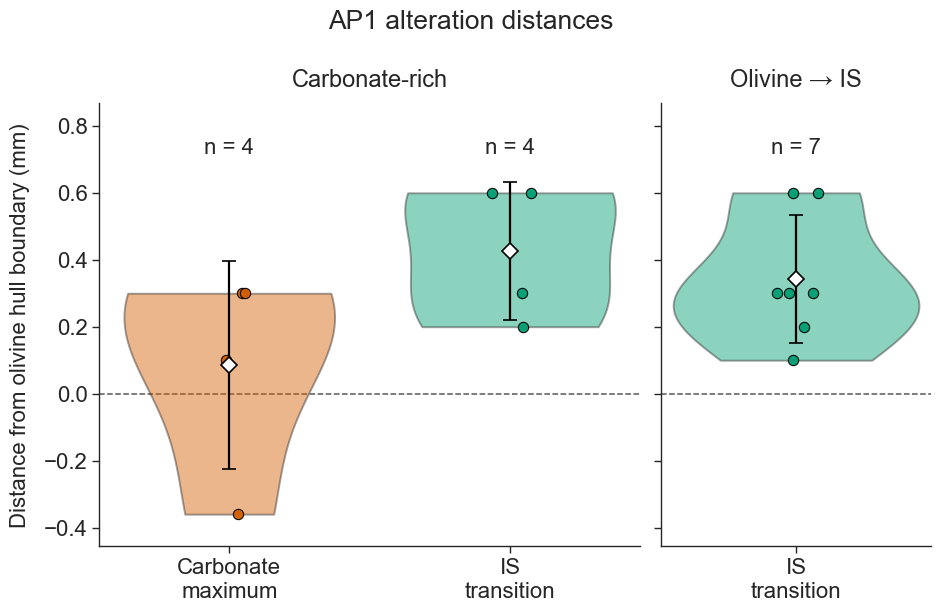

Saved PDF to: /Users/a19167/Desktop/PIXL/Carbonate_Research/920/Results/AP1_alteration_distances.pdf


In [32]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ap1_df = pd.DataFrame({
    "Cluster_category": (
        ["Carbonate-rich"] * 4 +
        ["Carbonate-rich"] * 4 +
        ["Olivine → IS"] * 7
    ),
    "Distance_metric": (
        ["Carbonate-maximum distance"] * 4 +
        ["IS transition distance"] * 4 +
        ["IS transition distance"] * 7
    ),
    "Distance_mm": [
        # Carbonate-rich clusters: carbonate-maximum distances
         0.30, 0.10, 0.30, -0.36,

        # Carbonate-rich clusters: IS transition distances
         0.60, 0.60, 0.30, 0.20,

        # Olivine → IS clusters: IS transition distances
         0.30, 0.60, 0.30, 0.60, 0.20, 0.30, 0.10,
    ],
    "Cluster_ID": [
        "CR1", "CR2", "CR3", "CR4",
        "CR1", "CR2", "CR3", "CR4",
        "OI1", "OI2", "OI3", "OI4", "OI5", "OI6", "OI7",
    ],
})

# ------------------------------------------------------------
# Confirm means and sample standard deviations
# ------------------------------------------------------------

summary_df = (
    ap1_df
    .groupby(
        ["Cluster_category", "Distance_metric"],
        sort=False,
    )["Distance_mm"]
    .agg(n="count", mean="mean", stdev="std")
    .reset_index()
)

print("AP1 cluster-level data:")
print(ap1_df)

print("\nSummary statistics:")
print(summary_df)

# ------------------------------------------------------------
# Plot formatting
# ------------------------------------------------------------

sns.set_theme(style="ticks", context="paper")

# Font sizes
figure_title_fontsize = 19
panel_title_fontsize = 17
axis_label_fontsize = 16
tick_fontsize = 16
n_label_fontsize = 16

category_order = [
    "Carbonate-rich",
    "Olivine → IS",
]

metric_order = {
    "Carbonate-rich": [
        "Carbonate-maximum distance",
        "IS transition distance",
    ],
    "Olivine → IS": [
        "IS transition distance",
    ],
}

palette = {
    "Carbonate-maximum distance": "#D55E00",
    "IS transition distance": "#009E73",
}

# Common y-axis limits leave room for the sample-size labels.
ymin = ap1_df["Distance_mm"].min()
ymax = ap1_df["Distance_mm"].max()
data_range = ymax - ymin

lower_limit = ymin - 0.10 * data_range
upper_limit = ymax + 0.28 * data_range
n_label_y = ymax + 0.14 * data_range

# ------------------------------------------------------------
# Create two-panel violin plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(9.5, 6.0),
    sharey=True,
    gridspec_kw={"width_ratios": [2, 1]},
)

# Reproducible jitter for individual points
rng = np.random.default_rng(42)

for ax, category in zip(axes, category_order):

    panel_data = ap1_df.loc[
        ap1_df["Cluster_category"] == category
    ].copy()

    order = metric_order[category]

    # Violin distributions
    sns.violinplot(
        data=panel_data,
        x="Distance_metric",
        y="Distance_mm",
        order=order,
        palette=palette,
        hue="Distance_metric",
        hue_order=order,
        legend=False,
        inner=None,
        cut=0,
        linewidth=1.4,
        width=0.75,
        saturation=1,
        ax=ax,
    )

    # Make violin fills semi-transparent
    for collection in ax.collections:
        collection.set_alpha(0.45)

    # Add individual cluster measurements and mean ± SD
    for x_position, metric in enumerate(order):

        values = panel_data.loc[
            panel_data["Distance_metric"] == metric,
            "Distance_mm",
        ].to_numpy()

        jitter = rng.uniform(-0.08, 0.08, size=len(values))

        # Individual clusters
        ax.scatter(
            x_position + jitter,
            values,
            s=55,
            color=palette[metric],
            edgecolor="black",
            linewidth=0.8,
            alpha=0.95,
            zorder=4,
        )

        # Mean and sample standard deviation
        mean = values.mean()
        stdev = values.std(ddof=1)

        ax.errorbar(
            x_position,
            mean,
            yerr=stdev,
            fmt="D",
            markersize=8,
            markerfacecolor="white",
            markeredgecolor="black",
            markeredgewidth=1.2,
            ecolor="black",
            elinewidth=1.6,
            capsize=5,
            capthick=1.6,
            zorder=5,
        )

        # Sample size
        ax.text(
            x_position,
            n_label_y,
            f"n = {len(values)}",
            ha="center",
            va="center",
            fontsize=n_label_fontsize,
        )

    # Olivine hull boundary
    ax.axhline(
        0,
        color="0.35",
        linestyle="--",
        linewidth=1.1,
        zorder=0,
    )

    ax.set_ylim(lower_limit, upper_limit)
    ax.set_title(
        category,
        fontsize=panel_title_fontsize,
        pad=12,
    )
    ax.set_xlabel("")
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
    )

    sns.despine(ax=ax)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

axes[0].set_ylabel(
    "Distance from olivine hull boundary (mm)",
    fontsize=axis_label_fontsize,
    labelpad=10,
)

axes[1].set_ylabel("")

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(
    ["Carbonate\nmaximum", "IS\ntransition"],
    fontsize=tick_fontsize,
)

axes[1].set_xticks([0])
axes[1].set_xticklabels(
    ["IS\ntransition"],
    fontsize=tick_fontsize,
)

fig.suptitle(
    "AP1 alteration distances",
    fontsize=figure_title_fontsize,
    y=1.01,
)

fig.tight_layout()

# ------------------------------------------------------------
# Save and display
# ------------------------------------------------------------

png_path = os.path.join(
    outdir_root,
    "AP1_alteration_distances.png",
)

pdf_path = os.path.join(
    outdir_root,
    "AP1_alteration_distances.pdf",
)

plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print(f"Saved PDF to: {pdf_path}")